In [19]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from datetime import datetime
import warnings
warnings.filterwarnings('ignore')

# Set style
plt.style.use('seaborn-v0_8-darkgrid')
sns.set_palette("husl")

# Load your data
df = pd.read_csv(r"D:\Download Crome\ADs Tracking - influncer tracking .csv")

print("Dataset shape:", df.shape)
df.head(10)

Dataset shape: (109, 9)


,`branch,Date,Influencer Name,Active?,Leads Today,Cost/Lead,Reach,Amount Spent,Remarks
0,moga,13August,gill rupinder,yes,1,101,NaN,101,NaN
1,frenchise,13August,sasta vloger,yes,7,223,NaN,NaN,NaN
2,omex,13August,pahul,yes,12,54,NaN,656,NaN
3,sec32,13August,pb10junction,yes,4,128,NaN,513,NaN
4,moga,13August,navjot vloges,yes,8,122,NaN,983,NaN
5,sec32,15August,PB 10 Jeaction,no,5,284,NaN,1421,Complete
6,omex,15August,Paul Gambhir,yes,9,49,NaN,1473,NaN
7,moga,15August,navjot vloges,yes,4,190,NaN,450,NaN
8,moga,15August,gill rupinder,yes,7,75,NaN,832,NaN
9,moga,15August,i am moga 29,yes,5,61,NaN,306,NaN


In [20]:
# First, rename the column to remove backticks
# Check if column has backticks
if '`branch`' in df.columns:
    df.rename(columns={'`branch`': 'branch'}, inplace=True)
elif 'branch' in df.columns:
    pass  # Already correct
else:
    # Check for any column that might contain 'branch'
    for col in df.columns:
        if 'branch' in col.lower():
            df.rename(columns={col: 'branch'}, inplace=True)
            break

# 1. Clean Date column
def clean_date(date_val):
    if pd.isna(date_val):
        return pd.NaT
    date_str = str(date_val).strip()
    
    # Handle '15 Augest' -> '15-Aug'
    date_str = date_str.replace('Augest', 'Aug')
    date_str = date_str.replace('Augest', 'Aug')
    
    # Handle '27 Augest' -> '27-Aug'
    if ' ' in date_str and not '-' in date_str:
        parts = date_str.split()
        if len(parts) == 2:
            date_str = f"{parts[0]}-{parts[1][:3]}"
    
    # Handle '15 August' -> '15-Aug'
    date_str = date_str.replace('August', 'Aug')
    
    try:
        return pd.to_datetime(date_str, format='%d-%b')
    except:
        try:
            return pd.to_datetime(date_str)
        except:
            return pd.NaT

df['Clean_Date'] = df['Date'].apply(clean_date)
df['Date'] = df['Clean_Date']
df.drop('Clean_Date', axis=1, inplace=True)

# 2. Clean numeric columns
def clean_numeric(val):
    if pd.isna(val) or val == '' or val == '___' or val == '____':
        return np.nan
    if isinstance(val, (int, float)):
        return val
    cleaned = str(val).replace('₹', '').replace(',', '').strip()
    try:
        return float(cleaned)
    except:
        return np.nan

numeric_cols = ['Leads Today', 'Cost/Lead', 'Reach', 'Amount Spent']
for col in numeric_cols:
    if col in df.columns:
        df[col] = df[col].apply(clean_numeric)

# 3. Clean Active column
if 'Active?' in df.columns:
    df['Active'] = df['Active?'].apply(lambda x: 1 if str(x).lower() in ['yes', 'y', '1', 'true'] else 0)

# 4. Clean Remarks
if 'Remarks' in df.columns:
    df['Remarks_Clean'] = df['Remarks'].fillna('')

# 5. Extract month and day
df['Month'] = df['Date'].dt.strftime('%b')
df['Day'] = df['Date'].dt.day
df['Date_Formatted'] = df['Date'].dt.strftime('%d-%b')

# 6. Calculate missing Amount Spent
mask = df['Amount Spent'].isna() & df['Leads Today'].notna() & df['Cost/Lead'].notna()
df.loc[mask, 'Amount Spent'] = df.loc[mask, 'Leads Today'] * df.loc[mask, 'Cost/Lead']

# 7. Calculate missing Cost per Lead
mask = df['Cost/Lead'].isna() & df['Amount Spent'].notna() & df['Leads Today'].notna() & (df['Leads Today'] > 0)
df.loc[mask, 'Cost/Lead'] = df.loc[mask, 'Amount Spent'] / df.loc[mask, 'Leads Today']

# 8. Calculate ROI metrics
df['Cost_Per_Lead'] = df.apply(lambda row: row['Amount Spent'] / row['Leads Today'] if row['Leads Today'] > 0 else np.nan, axis=1)
df['Cost_Per_Reach'] = df.apply(lambda row: row['Amount Spent'] / row['Reach'] if row['Reach'] > 0 else np.nan, axis=1)
df['Lead_To_Reach_Ratio'] = df.apply(lambda row: (row['Leads Today'] / row['Reach']) * 100 if row['Reach'] > 0 else np.nan, axis=1)

# 9. Branch cleanup
df['Branch'] = df['branch'].str.strip().str.lower()
df['Branch'] = df['Branch'].replace({
    'frenchise': 'franchise',
    'franchise': 'franchise',
    'model town': 'model_town',
    'sec32': 'sector_32',
    'omex': 'omex',
    'moga': 'moga',
    'phagwara': 'phagwara',
    'hoshiarpur': 'hoshiarpur'
})

# Drop rows with no leads or no spend
df_clean = df[df['Leads Today'].notna() & df['Amount Spent'].notna()].copy()

print(f"Cleaned dataset: {len(df_clean)} rows")
print("\nAll columns in dataset:")
print(df_clean.columns.tolist())
print("\nFirst few rows:")
print(df_clean.head())

Cleaned dataset: 101 rows

All columns in dataset:
['branch', 'Date', 'Influencer Name', 'Active?', 'Leads Today', 'Cost/Lead', 'Reach', 'Amount Spent', 'Remarks', 'Active', 'Remarks_Clean', 'Month', 'Day', 'Date_Formatted', 'Cost_Per_Lead', 'Cost_Per_Reach', 'Lead_To_Reach_Ratio', 'Branch']

First few rows:
       branch Date Influencer Name Active?  Leads Today  Cost/Lead  Reach  \
0        moga  NaT   gill rupinder     yes          1.0      101.0    NaN   
1  frenchise   NaT    sasta vloger     yes          7.0      223.0    NaN   
2        omex  NaT           pahul     yes         12.0       54.0    NaN   
3       sec32  NaT    pb10junction     yes          4.0      128.0    NaN   
4        moga  NaT   navjot vloges     yes          8.0      122.0    NaN   

   Amount Spent Remarks  Active Remarks_Clean Month  Day Date_Formatted  \
0         101.0     NaN       1                 NaN  NaN            NaN   
1        1561.0     NaN       1                 NaN  NaN            NaN   
2 

In [21]:
# 1. Clean Date column
def clean_date(date_val):
    if pd.isna(date_val):
        return pd.NaT
    date_str = str(date_val).strip()
    
    # Handle '15 Augest' -> '15-Aug'
    date_str = date_str.replace('Augest', 'Aug')
    date_str = date_str.replace('Augest', 'Aug')
    
    # Handle '27 Augest' -> '27-Aug'
    if ' ' in date_str and not '-' in date_str:
        parts = date_str.split()
        if len(parts) == 2:
            date_str = f"{parts[0]}-{parts[1][:3]}"
    
    # Handle '15 August' -> '15-Aug'
    date_str = date_str.replace('August', 'Aug')
    
    try:
        return pd.to_datetime(date_str, format='%d-%b')
    except:
        try:
            return pd.to_datetime(date_str)
        except:
            return pd.NaT

df['Clean_Date'] = df['Date'].apply(clean_date)
df['Date'] = df['Clean_Date']
df.drop('Clean_Date', axis=1, inplace=True)

# 2. Clean numeric columns
# Remove special characters and convert
def clean_numeric(val):
    if pd.isna(val) or val == '' or val == '___' or val == '____':
        return np.nan
    if isinstance(val, (int, float)):
        return val
    # Remove currency symbols, commas, etc.
    cleaned = str(val).replace('₹', '').replace(',', '').strip()
    try:
        return float(cleaned)
    except:
        return np.nan

numeric_cols = ['Leads Today', 'Cost/Lead', 'Reach', 'Amount Spent']
for col in numeric_cols:
    df[col] = df[col].apply(clean_numeric)

# 3. Clean Active column
df['Active'] = df['Active?'].apply(lambda x: 1 if str(x).lower() in ['yes', 'y', '1', 'true'] else 0)

# 4. Clean Remarks
df['Remarks_Clean'] = df['Remarks'].fillna('')

# 5. Extract month and day
df['Month'] = df['Date'].dt.strftime('%b')
df['Day'] = df['Date'].dt.day
df['Date_Formatted'] = df['Date'].dt.strftime('%d-%b')

# 6. Calculate missing Amount Spent from Cost/Lead * Leads
mask = df['Amount Spent'].isna() & df['Leads Today'].notna() & df['Cost/Lead'].notna()
df.loc[mask, 'Amount Spent'] = df.loc[mask, 'Leads Today'] * df.loc[mask, 'Cost/Lead']

# 7. Calculate Cost per Lead if missing
mask = df['Cost/Lead'].isna() & df['Amount Spent'].notna() & df['Leads Today'].notna() & (df['Leads Today'] > 0)
df.loc[mask, 'Cost/Lead'] = df.loc[mask, 'Amount Spent'] / df.loc[mask, 'Leads Today']

# 8. Calculate ROI metrics
df['Cost_Per_Lead'] = df['Amount Spent'] / df['Leads Today']
df['Cost_Per_Reach'] = df['Amount Spent'] / df['Reach']
df['Lead_To_Reach_Ratio'] = (df['Leads Today'] / df['Reach']) * 100

# 9. Branch cleanup
df['Branch'] = df['branch'].str.strip().str.lower()
df['Branch'] = df['Branch'].replace({
    'frenchise': 'franchise',
    'franchise': 'franchise',
    'model town': 'model_town',
    'sec32': 'sector_32',
    'omex': 'omex',
    'moga': 'moga',
    'phagwara': 'phagwara',
    'hoshiarpur': 'hoshiarpur'
})

# Drop rows with no leads or no spend
df_clean = df[df['Leads Today'].notna() & df['Amount Spent'].notna()].copy()

print(f"Cleaned dataset: {len(df_clean)} rows")
print("\nData types after cleaning:")
print(df_clean.dtypes)

Cleaned dataset: 101 rows

Data types after cleaning:
branch                         object
Date                   datetime64[ns]
Influencer Name                object
Active?                        object
Leads Today                   float64
Cost/Lead                     float64
Reach                         float64
Amount Spent                  float64
Remarks                        object
Active                          int64
Remarks_Clean                  object
Month                          object
Day                           float64
Date_Formatted                 object
Cost_Per_Lead                 float64
Cost_Per_Reach                float64
Lead_To_Reach_Ratio           float64
Branch                         object
dtype: object


In [22]:
# ======================== KEY METRICS ========================

# 1. Overall Performance
total_leads = df_clean['Leads Today'].sum()
total_spend = df_clean['Amount Spent'].sum()
total_reach = df_clean['Reach'].sum()
avg_cost_per_lead = total_spend / total_leads
avg_cost_per_reach = total_spend / total_reach
lead_conversion_rate = (total_leads / total_reach) * 100

# 2. Number of Influencers
total_influencers = df_clean['Influencer Name'].nunique()
active_influencers = df_clean[df_clean['Active'] == 1]['Influencer Name'].nunique()

# 3. Branches
total_branches = df_clean['Branch'].nunique()

print("="*70)
print("📊 INFLUENCER MARKETING DASHBOARD - KEY METRICS")
print("="*70)
print(f"""
📈 OVERALL PERFORMANCE:
   Total Leads Generated:      {total_leads:,.0f}
   Total Amount Spent:         ₹{total_spend:,.0f}
   Total Reach:                {total_reach:,.0f}
   Avg Cost per Lead:          ₹{avg_cost_per_lead:,.2f}
   Avg Cost per 1000 Reach:    ₹{avg_cost_per_reach*1000:,.2f}
   Lead Conversion Rate:       {lead_conversion_rate:.2f}%

👥 INFLUENCERS:
   Total Influencers:          {total_influencers}
   Active Influencers:         {active_influencers}
   Inactive Influencers:       {total_influencers - active_influencers}

🏢 BRANCHES:
   Total Branches:             {total_branches}
""")

📊 INFLUENCER MARKETING DASHBOARD - KEY METRICS

📈 OVERALL PERFORMANCE:
   Total Leads Generated:      1,195
   Total Amount Spent:         ₹95,334
   Total Reach:                163,494
   Avg Cost per Lead:          ₹79.78
   Avg Cost per 1000 Reach:    ₹583.11
   Lead Conversion Rate:       0.73%

👥 INFLUENCERS:
   Total Influencers:          30
   Active Influencers:         29
   Inactive Influencers:       1

🏢 BRANCHES:
   Total Branches:             7



In [23]:
# Top Performing Influencers
influencer_performance = df_clean.groupby('Influencer Name').agg({
    'Leads Today': 'sum',
    'Amount Spent': 'sum',
    'Reach': 'sum',
    'Cost/Lead': 'mean',
    'Active': 'count'
}).reset_index()

influencer_performance['Cost_Per_Lead'] = influencer_performance['Amount Spent'] / influencer_performance['Leads Today']
influencer_performance['Leads_Per_1000_Reach'] = (influencer_performance['Leads Today'] / influencer_performance['Reach']) * 1000
influencer_performance['Efficiency_Score'] = influencer_performance['Leads Today'] / (influencer_performance['Amount Spent'] / 1000)

# Rank by leads
top_influencers = influencer_performance.sort_values('Leads Today', ascending=False)

print("\n🏆 TOP 10 INFLUENCERS BY LEADS:")
print("="*80)
display(top_influencers.head(10)[['Influencer Name', 'Leads Today', 'Amount Spent', 'Cost_Per_Lead', 'Reach']])

# Most Cost-Effective Influencers
print("\n💰 TOP 10 MOST COST-EFFECTIVE INFLUENCERS (Lowest Cost/Lead):")
print("="*80)
cost_effective = influencer_performance[influencer_performance['Leads Today'] > 5].sort_values('Cost_Per_Lead')
display(cost_effective.head(10)[['Influencer Name', 'Cost_Per_Lead', 'Leads Today', 'Amount Spent']])


🏆 TOP 10 INFLUENCERS BY LEADS:


,Influencer Name,Leads Today,Amount Spent,Cost_Per_Lead,Reach
16,brothers vlogs,158.0,4190.00,26.518987,36496.0
25,phagwara crettor,130.0,6541.00,50.315385,0.0
19,himangi,115.0,11190.00,97.304348,21224.0
4,Kajal Verma,91.0,3807.00,41.835165,0.0
20,i am moga 29,82.0,4835.00,58.963415,0.0
12,Paul Gambhir,72.0,6745.00,93.680556,0.0
22,navjot vloges,70.0,6146.00,87.800000,0.0
15,Taranvir Grewal,65.0,3400.25,52.311538,42436.0
7,Kirat Vlogs,54.0,1841.00,34.092593,0.0
27,sonu trander,52.0,4328.00,83.230769,0.0



💰 TOP 10 MOST COST-EFFECTIVE INFLUENCERS (Lowest Cost/Lead):


,Influencer Name,Cost_Per_Lead,Leads Today,Amount Spent
16,brothers vlogs,26.518987,158.0,4190.00
7,Kirat Vlogs,34.092593,54.0,1841.00
4,Kajal Verma,41.835165,91.0,3807.00
25,phagwara crettor,50.315385,130.0,6541.00
15,Taranvir Grewal,52.311538,65.0,3400.25
23,pahul,54.666667,12.0,656.00
1,Amarjit Kaur,58.454545,11.0,643.00
20,i am moga 29,58.963415,82.0,4835.00
17,buta,59.653846,26.0,1551.00
27,sonu trander,83.230769,52.0,4328.00



📊 BRANCH PERFORMANCE COMPARISON:


,Branch,Leads Today,Amount Spent,Reach,Influencer Name,Cost_Per_Lead,Leads_Per_Influencer,Efficiency
5,phagwara,370.0,21931.00,7268.0,5,59.272973,74.000000,16.871096
1,hoshiarpur,228.0,11806.00,92566.0,8,51.780702,28.500000,19.312214
4,omex,218.0,19871.25,42436.0,5,91.152523,43.600000,10.970623
3,moga,160.0,11914.00,0.0,3,74.462500,53.333333,13.429579
2,model_town,124.0,12890.00,21224.0,3,103.951613,41.333333,9.619860
6,sector_32,65.0,8321.00,0.0,5,128.015385,13.000000,7.811561
0,franchise,30.0,8601.00,0.0,1,286.700000,30.000000,3.487967


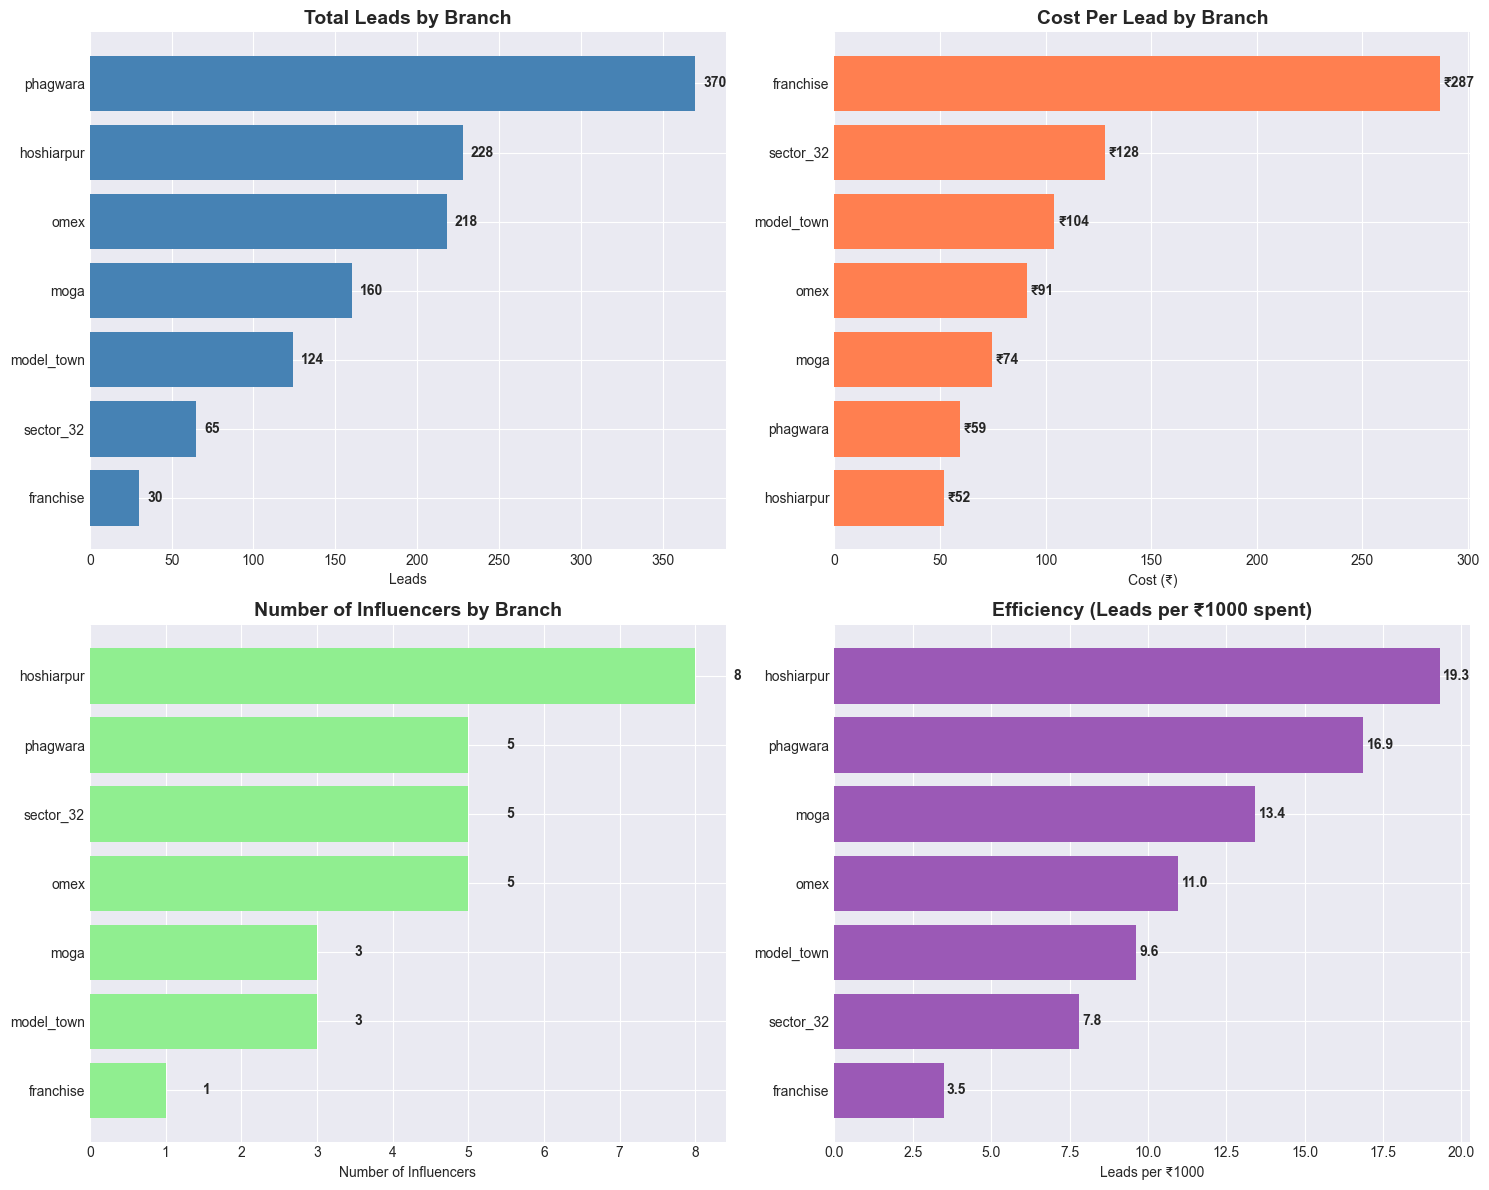

In [24]:
# Branch Performance
branch_performance = df_clean.groupby('Branch').agg({
    'Leads Today': 'sum',
    'Amount Spent': 'sum',
    'Reach': 'sum',
    'Influencer Name': 'nunique'
}).reset_index()

branch_performance['Cost_Per_Lead'] = branch_performance['Amount Spent'] / branch_performance['Leads Today']
branch_performance['Leads_Per_Influencer'] = branch_performance['Leads Today'] / branch_performance['Influencer Name']
branch_performance['Efficiency'] = branch_performance['Leads Today'] / (branch_performance['Amount Spent'] / 1000)

print("\n📊 BRANCH PERFORMANCE COMPARISON:")
print("="*80)
display(branch_performance.sort_values('Leads Today', ascending=False))

# Visualization
fig, axes = plt.subplots(2, 2, figsize=(15, 12))

# 1. Leads by Branch
ax1 = axes[0, 0]
branch_performance_sorted = branch_performance.sort_values('Leads Today', ascending=True)
bars = ax1.barh(branch_performance_sorted['Branch'], branch_performance_sorted['Leads Today'], 
                color='steelblue')
ax1.set_title('Total Leads by Branch', fontsize=14, fontweight='bold')
ax1.set_xlabel('Leads')
for i, v in enumerate(branch_performance_sorted['Leads Today']):
    ax1.text(v + 5, i, f'{v:.0f}', va='center', fontweight='bold')

# 2. Cost per Lead by Branch
ax2 = axes[0, 1]
branch_cost = branch_performance.sort_values('Cost_Per_Lead', ascending=True)
ax2.barh(branch_cost['Branch'], branch_cost['Cost_Per_Lead'], color='coral')
ax2.set_title('Cost Per Lead by Branch', fontsize=14, fontweight='bold')
ax2.set_xlabel('Cost (₹)')
for i, v in enumerate(branch_cost['Cost_Per_Lead']):
    ax2.text(v + 2, i, f'₹{v:.0f}', va='center', fontweight='bold')

# 3. Influencer Count by Branch
ax3 = axes[1, 0]
branch_influencers = branch_performance.sort_values('Influencer Name', ascending=True)
ax3.barh(branch_influencers['Branch'], branch_influencers['Influencer Name'], color='lightgreen')
ax3.set_title('Number of Influencers by Branch', fontsize=14, fontweight='bold')
ax3.set_xlabel('Number of Influencers')
for i, v in enumerate(branch_influencers['Influencer Name']):
    ax3.text(v + 0.5, i, f'{v:.0f}', va='center', fontweight='bold')

# 4. Efficiency (Leads per ₹1000 spent)
ax4 = axes[1, 1]
branch_efficiency = branch_performance.sort_values('Efficiency', ascending=True)
ax4.barh(branch_efficiency['Branch'], branch_efficiency['Efficiency'], color='#9b59b6')
ax4.set_title('Efficiency (Leads per ₹1000 spent)', fontsize=14, fontweight='bold')
ax4.set_xlabel('Leads per ₹1000')
for i, v in enumerate(branch_efficiency['Efficiency']):
    ax4.text(v + 0.1, i, f'{v:.1f}', va='center', fontweight='bold')

plt.tight_layout()
plt.show()


📅 TOP 5 BEST DAYS (By Leads):


,Date,Leads Today,Amount Spent,Reach,Influencer Name,Cost_Per_Lead
3,2026-08-27,180.0,14120.00,20939.0,11,78.444444
2,2026-08-26,143.0,6751.25,0.0,7,47.211538
6,2026-09-02,42.0,3776.00,0.0,8,89.904762
7,2026-09-03,31.0,3423.00,0.0,4,110.419355
1,2026-08-17,28.0,6643.00,0.0,5,237.250000



📅 TOP 5 WORST DAYS (By Leads):


,Date,Leads Today,Amount Spent,Reach,Influencer Name,Cost_Per_Lead
0,2026-08-15,2.0,879.0,0.0,1,439.500000
4,2026-08-31,9.0,614.0,42436.0,2,68.222222
5,2026-09-01,13.0,1085.0,0.0,4,83.461538
1,2026-08-17,28.0,6643.0,0.0,5,237.250000
7,2026-09-03,31.0,3423.0,0.0,4,110.419355


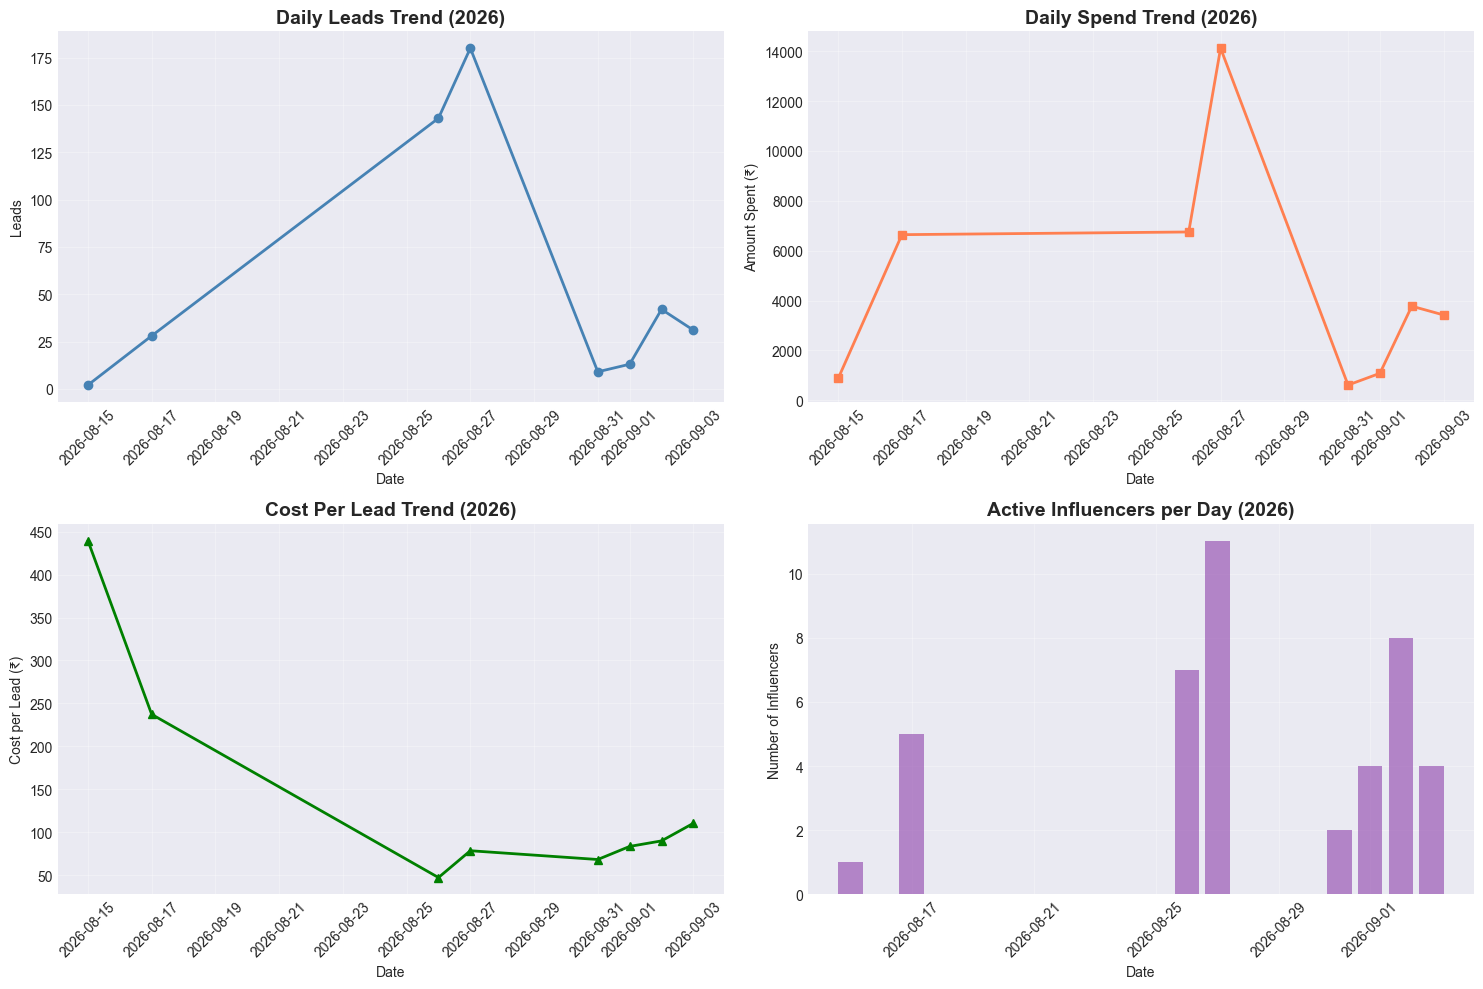


📊 2026 Performance Summary:
Total Days Analyzed: 8
Total Leads Generated: 448
Total Amount Spent: ₹37,291.25
Average Daily Leads: 56.00
Average Daily Spend: ₹4661.41
Overall Cost per Lead: ₹83.24
Average Cost per Lead: ₹144.30

📅 Date Range: 15-Aug-2026 to 03-Sep-2026


In [25]:
# Before the Daily Performance section, add this to fix the year
# Set all dates to 2026
df_clean['Date'] = df_clean['Date'].apply(lambda x: x.replace(year=2026) if pd.notna(x) else x)

# Now your Daily Performance code with 2026 dates
# Daily Performance
daily_performance = df_clean.groupby('Date').agg({
    'Leads Today': 'sum',
    'Amount Spent': 'sum',
    'Reach': 'sum',
    'Influencer Name': 'nunique'
}).reset_index()

# Sort by date to ensure proper trend display
daily_performance = daily_performance.sort_values('Date')

# Calculate Cost per Lead (avoid division by zero)
daily_performance['Cost_Per_Lead'] = daily_performance.apply(
    lambda row: row['Amount Spent'] / row['Leads Today'] if row['Leads Today'] > 0 else 0, 
    axis=1
)

# Find best and worst days
print("\n📅 TOP 5 BEST DAYS (By Leads):")
print("="*50)
display(daily_performance.sort_values('Leads Today', ascending=False).head(5))

print("\n📅 TOP 5 WORST DAYS (By Leads):")
print("="*50)
display(daily_performance.sort_values('Leads Today', ascending=True).head(5))

# Visualization with proper date formatting
fig, axes = plt.subplots(2, 2, figsize=(15, 10))

# 1. Daily Leads Trend
ax1 = axes[0, 0]
ax1.plot(daily_performance['Date'], daily_performance['Leads Today'], 
         marker='o', linewidth=2, color='steelblue')
ax1.set_title('Daily Leads Trend (2026)', fontsize=14, fontweight='bold')
ax1.set_xlabel('Date')
ax1.set_ylabel('Leads')
ax1.tick_params(axis='x', rotation=45)
ax1.grid(True, alpha=0.3)

# 2. Daily Spend Trend
ax2 = axes[0, 1]
ax2.plot(daily_performance['Date'], daily_performance['Amount Spent'], 
         marker='s', linewidth=2, color='coral')
ax2.set_title('Daily Spend Trend (2026)', fontsize=14, fontweight='bold')
ax2.set_xlabel('Date')
ax2.set_ylabel('Amount Spent (₹)')
ax2.tick_params(axis='x', rotation=45)
ax2.grid(True, alpha=0.3)

# 3. Cost per Lead over time
ax3 = axes[1, 0]
ax3.plot(daily_performance['Date'], daily_performance['Cost_Per_Lead'], 
         marker='^', linewidth=2, color='green')
ax3.set_title('Cost Per Lead Trend (2026)', fontsize=14, fontweight='bold')
ax3.set_xlabel('Date')
ax3.set_ylabel('Cost per Lead (₹)')
ax3.tick_params(axis='x', rotation=45)
ax3.grid(True, alpha=0.3)

# 4. Active Influencers per day
ax4 = axes[1, 1]
ax4.bar(daily_performance['Date'], daily_performance['Influencer Name'], 
        color='#9b59b6', alpha=0.7)
ax4.set_title('Active Influencers per Day (2026)', fontsize=14, fontweight='bold')
ax4.set_xlabel('Date')
ax4.set_ylabel('Number of Influencers')
ax4.tick_params(axis='x', rotation=45)
ax4.grid(True, alpha=0.3)

plt.tight_layout()
plt.show()

# Additional 2026-specific analysis
print("\n📊 2026 Performance Summary:")
print("="*50)
print(f"Total Days Analyzed: {len(daily_performance)}")
print(f"Total Leads Generated: {daily_performance['Leads Today'].sum():,.0f}")
print(f"Total Amount Spent: ₹{daily_performance['Amount Spent'].sum():,.2f}")
print(f"Average Daily Leads: {daily_performance['Leads Today'].mean():.2f}")
print(f"Average Daily Spend: ₹{daily_performance['Amount Spent'].mean():.2f}")
print(f"Overall Cost per Lead: ₹{daily_performance['Amount Spent'].sum() / daily_performance['Leads Today'].sum():.2f}")
print(f"Average Cost per Lead: ₹{daily_performance[daily_performance['Cost_Per_Lead'] > 0]['Cost_Per_Lead'].mean():.2f}")

# Show date range after fixing
print(f"\n📅 Date Range: {daily_performance['Date'].min().strftime('%d-%b-%Y')} to {daily_performance['Date'].max().strftime('%d-%b-%Y')}")


📊 ACTIVE vs INACTIVE INFLUENCERS:


,Active,Influencer Name,Leads Today,Amount Spent,Reach,Avg_Leads_Per_Influencer,Cost_Per_Lead
0,0,11,217.0,17584.25,42436.0,19.727273,81.033410
1,1,90,978.0,77750.00,121058.0,10.866667,79.498978


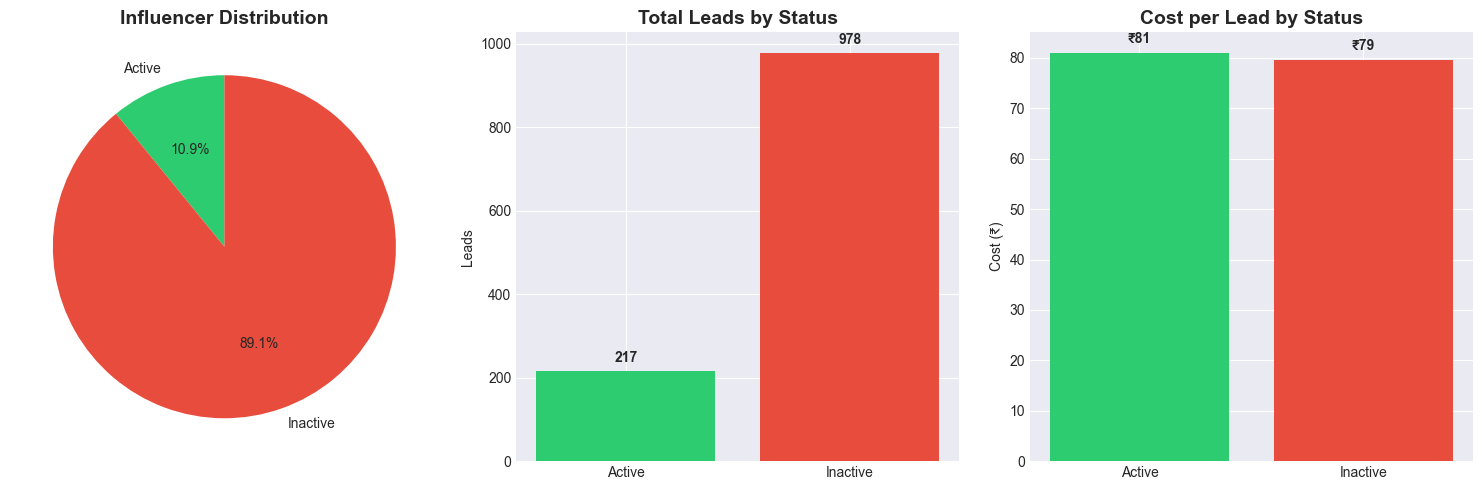

In [26]:
# Active vs Inactive Analysis
status_analysis = df_clean.groupby('Active').agg({
    'Influencer Name': 'count',
    'Leads Today': 'sum',
    'Amount Spent': 'sum',
    'Reach': 'sum'
}).reset_index()

status_analysis['Avg_Leads_Per_Influencer'] = status_analysis['Leads Today'] / status_analysis['Influencer Name']
status_analysis['Cost_Per_Lead'] = status_analysis['Amount Spent'] / status_analysis['Leads Today']

print("\n📊 ACTIVE vs INACTIVE INFLUENCERS:")
print("="*60)
display(status_analysis)

# Visualization
fig, axes = plt.subplots(1, 3, figsize=(15, 5))

# 1. Count
labels = ['Active', 'Inactive']
counts = status_analysis['Influencer Name'].values
axes[0].pie(counts, labels=labels, autopct='%1.1f%%', 
           colors=['#2ecc71', '#e74c3c'], startangle=90)
axes[0].set_title('Influencer Distribution', fontsize=14, fontweight='bold')

# 2. Leads by Status
axes[1].bar(labels, status_analysis['Leads Today'], color=['#2ecc71', '#e74c3c'])
axes[1].set_title('Total Leads by Status', fontsize=14, fontweight='bold')
axes[1].set_ylabel('Leads')
for i, v in enumerate(status_analysis['Leads Today']):
    axes[1].text(i, v + 20, f'{v:,.0f}', ha='center', fontweight='bold')

# 3. Cost per Lead
axes[2].bar(labels, status_analysis['Cost_Per_Lead'], color=['#2ecc71', '#e74c3c'])
axes[2].set_title('Cost per Lead by Status', fontsize=14, fontweight='bold')
axes[2].set_ylabel('Cost (₹)')
for i, v in enumerate(status_analysis['Cost_Per_Lead']):
    axes[2].text(i, v + 2, f'₹{v:.0f}', ha='center', fontweight='bold')

plt.tight_layout()
plt.show()


💰 COST PER LEAD DISTRIBUTION:


,Cost_Bracket,Influencer Name,Leads Today,Amount Spent
0,₹0-50,24,449.0,15093.25
1,₹51-100,32,412.0,27744.00
2,₹101-200,31,277.0,35074.00
3,₹201-300,8,46.0,11613.00
4,₹301-500,4,10.0,4206.00


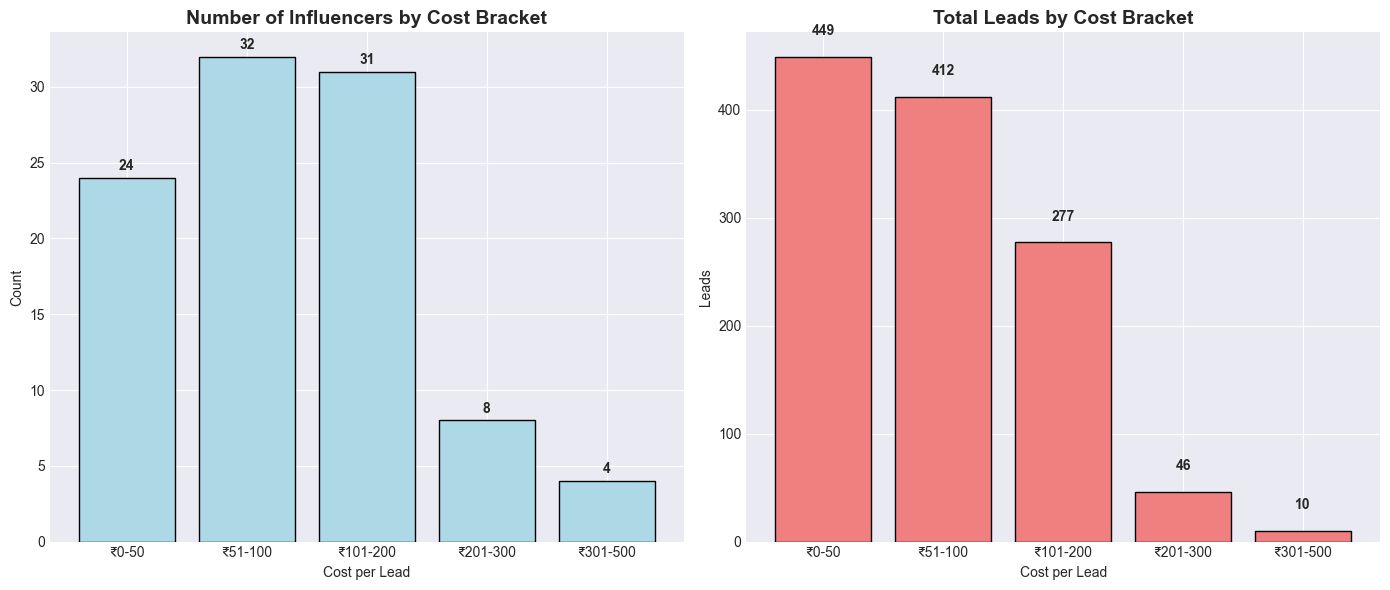

In [27]:
# Cost efficiency analysis
cost_distribution = df_clean[df_clean['Cost_Per_Lead'] < 500].copy()  # Remove outliers

# Create cost brackets
bins = [0, 50, 100, 200, 300, 500]
labels = ['₹0-50', '₹51-100', '₹101-200', '₹201-300', '₹301-500']
cost_distribution['Cost_Bracket'] = pd.cut(cost_distribution['Cost_Per_Lead'], 
                                            bins=bins, labels=labels, right=False)

cost_breakdown = cost_distribution.groupby('Cost_Bracket').agg({
    'Influencer Name': 'count',
    'Leads Today': 'sum',
    'Amount Spent': 'sum'
}).reset_index()

print("\n💰 COST PER LEAD DISTRIBUTION:")
print("="*60)
display(cost_breakdown)

# Visualization
fig, axes = plt.subplots(1, 2, figsize=(14, 6))

# 1. Count by Cost Bracket
axes[0].bar(cost_breakdown['Cost_Bracket'], cost_breakdown['Influencer Name'], 
            color='lightblue', edgecolor='black')
axes[0].set_title('Number of Influencers by Cost Bracket', fontsize=14, fontweight='bold')
axes[0].set_xlabel('Cost per Lead')
axes[0].set_ylabel('Count')
for i, v in enumerate(cost_breakdown['Influencer Name']):
    axes[0].text(i, v + 0.5, f'{v}', ha='center', fontweight='bold')

# 2. Leads by Cost Bracket
axes[1].bar(cost_breakdown['Cost_Bracket'], cost_breakdown['Leads Today'], 
            color='lightcoral', edgecolor='black')
axes[1].set_title('Total Leads by Cost Bracket', fontsize=14, fontweight='bold')
axes[1].set_xlabel('Cost per Lead')
axes[1].set_ylabel('Leads')
for i, v in enumerate(cost_breakdown['Leads Today']):
    axes[1].text(i, v + 20, f'{v:,.0f}', ha='center', fontweight='bold')

plt.tight_layout()
plt.show()


📊 INFLUENCER PERFORMANCE MATRIX:


,Category,Influencer Name,Leads Today,Cost_Per_Lead
0,"⚠️ Underperformers (Low Leads, High Cost)",14,110.0,98.729949
1,"⭐ Stars (High Leads, Low Cost)",14,1030.0,15.747756
2,"💰 Cost Efficient (Low Leads, Low Cost)",1,25.0,18.984000
3,"📊 Volume Drivers (High Leads, High Cost)",1,30.0,57.340000


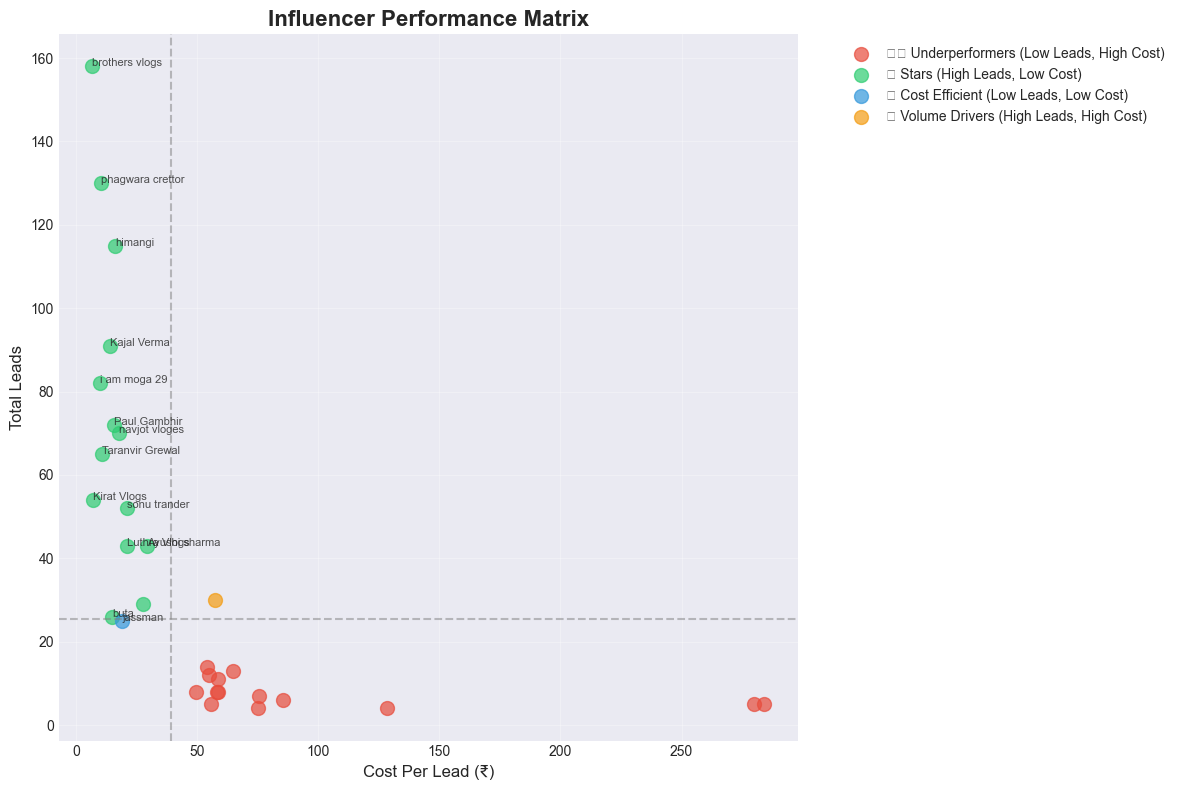

In [28]:
# Create performance matrix
performance_matrix = df_clean.groupby('Influencer Name').agg({
    'Leads Today': 'sum',
    'Amount Spent': 'mean',
    'Cost/Lead': 'mean',
    'Reach': 'sum'
}).reset_index()

# Calculate metrics
performance_matrix['Cost_Per_Lead'] = performance_matrix['Amount Spent'] / performance_matrix['Leads Today']
performance_matrix['Avg_Cost'] = performance_matrix['Amount Spent']

# Categorize into 4 quadrants
median_cost = performance_matrix['Cost_Per_Lead'].median()
median_leads = performance_matrix['Leads Today'].median()

def categorize(row):
    if row['Cost_Per_Lead'] <= median_cost and row['Leads Today'] >= median_leads:
        return '⭐ Stars (High Leads, Low Cost)'
    elif row['Cost_Per_Lead'] > median_cost and row['Leads Today'] >= median_leads:
        return '📊 Volume Drivers (High Leads, High Cost)'
    elif row['Cost_Per_Lead'] <= median_cost and row['Leads Today'] < median_leads:
        return '💰 Cost Efficient (Low Leads, Low Cost)'
    else:
        return '⚠️ Underperformers (Low Leads, High Cost)'

performance_matrix['Category'] = performance_matrix.apply(categorize, axis=1)

print("\n📊 INFLUENCER PERFORMANCE MATRIX:")
print("="*60)
category_summary = performance_matrix.groupby('Category').agg({
    'Influencer Name': 'count',
    'Leads Today': 'sum',
    'Cost_Per_Lead': 'mean'
}).reset_index()
display(category_summary)

# Visualization
fig, ax = plt.subplots(figsize=(12, 8))

colors = {
    '⭐ Stars (High Leads, Low Cost)': '#2ecc71',
    '📊 Volume Drivers (High Leads, High Cost)': '#f39c12',
    '💰 Cost Efficient (Low Leads, Low Cost)': '#3498db',
    '⚠️ Underperformers (Low Leads, High Cost)': '#e74c3c'
}

for category in performance_matrix['Category'].unique():
    subset = performance_matrix[performance_matrix['Category'] == category]
    ax.scatter(subset['Cost_Per_Lead'], subset['Leads Today'], 
               label=category, s=100, alpha=0.7, color=colors[category])

# Add influencer names
for _, row in performance_matrix.iterrows():
    if row['Leads Today'] > median_leads * 1.5 or row['Cost_Per_Lead'] < median_cost * 0.5:
        ax.annotate(row['Influencer Name'], 
                   (row['Cost_Per_Lead'], row['Leads Today']),
                   fontsize=8, alpha=0.8)

# Add quadrant lines
ax.axhline(y=median_leads, color='gray', linestyle='--', alpha=0.5)
ax.axvline(x=median_cost, color='gray', linestyle='--', alpha=0.5)

ax.set_xlabel('Cost Per Lead (₹)', fontsize=12)
ax.set_ylabel('Total Leads', fontsize=12)
ax.set_title('Influencer Performance Matrix', fontsize=16, fontweight='bold')
ax.legend(bbox_to_anchor=(1.05, 1), loc='upper left')
ax.grid(True, alpha=0.3)

plt.tight_layout()
plt.show()


📈 WEEKLY PERFORMANCE TREND:


,Week,Leads Today,Amount Spent,Reach,Cost_Per_Lead
0,33,2.0,879.00,0.0,439.500000
1,34,28.0,6643.00,0.0,237.250000
2,35,323.0,20871.25,20939.0,64.616873
3,36,95.0,8898.00,42436.0,93.663158


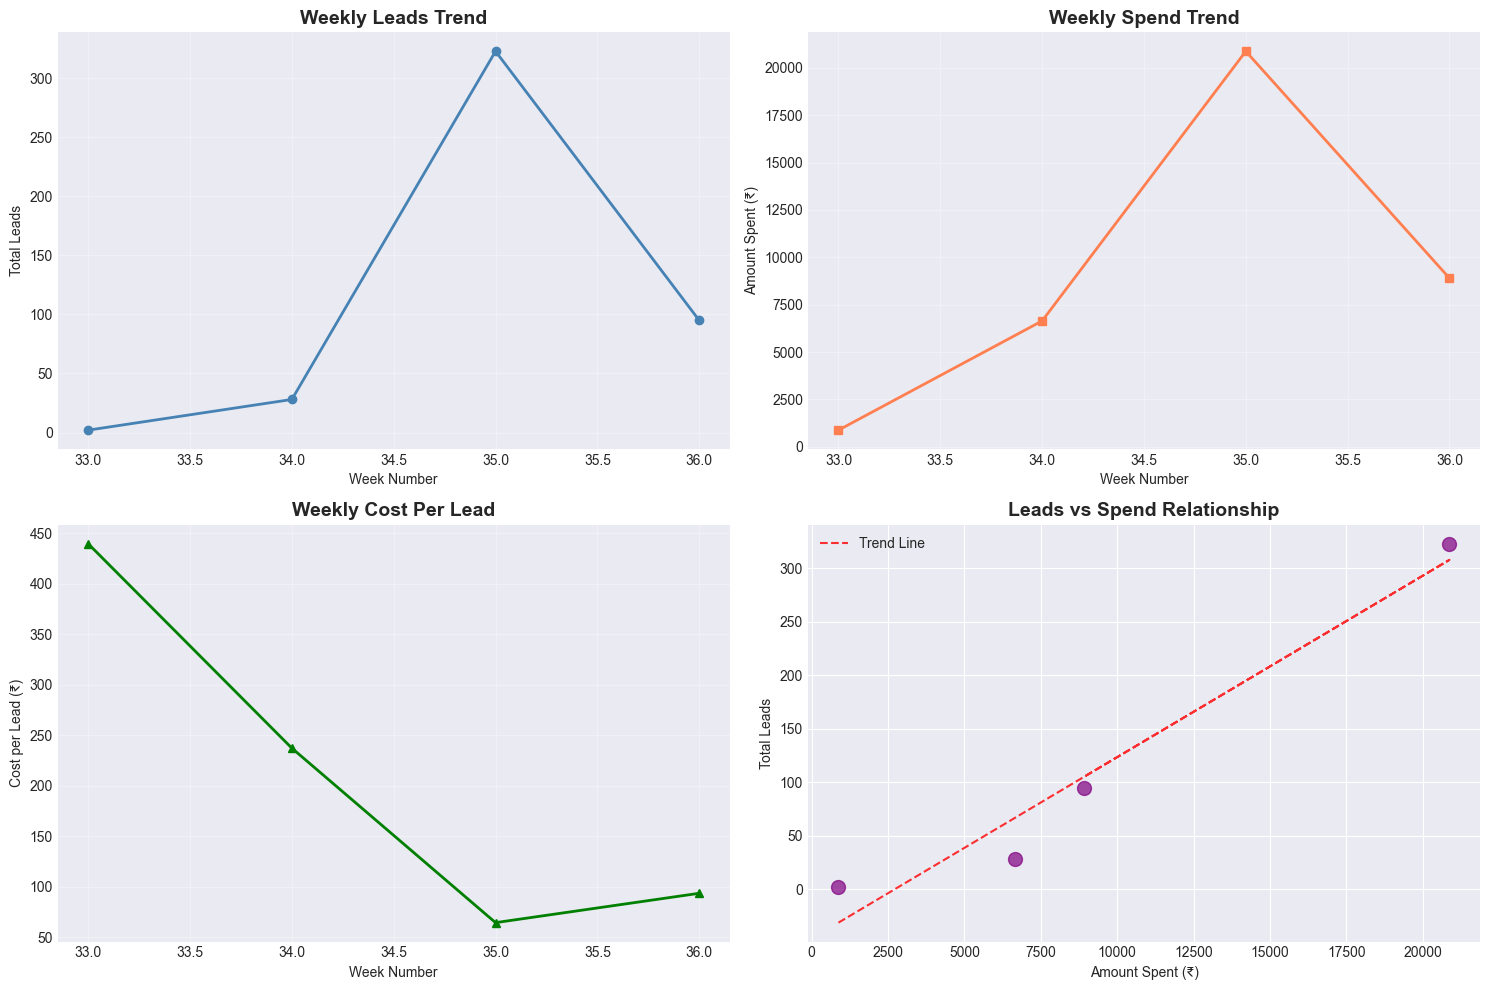

In [29]:
# Weekly aggregation for trend
df_clean['Week'] = df_clean['Date'].dt.isocalendar().week
weekly_data = df_clean.groupby('Week').agg({
    'Leads Today': 'sum',
    'Amount Spent': 'sum',
    'Reach': 'sum'
}).reset_index()

weekly_data['Cost_Per_Lead'] = weekly_data['Amount Spent'] / weekly_data['Leads Today']

print("\n📈 WEEKLY PERFORMANCE TREND:")
print("="*60)
display(weekly_data)

# Visualization
fig, axes = plt.subplots(2, 2, figsize=(15, 10))

# 1. Weekly Leads
ax1 = axes[0, 0]
ax1.plot(weekly_data['Week'], weekly_data['Leads Today'], 
         marker='o', linewidth=2, color='steelblue')
ax1.set_title('Weekly Leads Trend', fontsize=14, fontweight='bold')
ax1.set_xlabel('Week Number')
ax1.set_ylabel('Total Leads')
ax1.grid(True, alpha=0.3)

# 2. Weekly Spend
ax2 = axes[0, 1]
ax2.plot(weekly_data['Week'], weekly_data['Amount Spent'], 
         marker='s', linewidth=2, color='coral')
ax2.set_title('Weekly Spend Trend', fontsize=14, fontweight='bold')
ax2.set_xlabel('Week Number')
ax2.set_ylabel('Amount Spent (₹)')
ax2.grid(True, alpha=0.3)

# 3. Cost per Lead trend
ax3 = axes[1, 0]
ax3.plot(weekly_data['Week'], weekly_data['Cost_Per_Lead'], 
         marker='^', linewidth=2, color='green')
ax3.set_title('Weekly Cost Per Lead', fontsize=14, fontweight='bold')
ax3.set_xlabel('Week Number')
ax3.set_ylabel('Cost per Lead (₹)')
ax3.grid(True, alpha=0.3)

# 4. Leads vs Spend Relationship
ax4 = axes[1, 1]
ax4.scatter(weekly_data['Amount Spent'], weekly_data['Leads Today'], 
           s=100, alpha=0.7, color='purple')
ax4.set_title('Leads vs Spend Relationship', fontsize=14, fontweight='bold')
ax4.set_xlabel('Amount Spent (₹)')
ax4.set_ylabel('Total Leads')

# Add trend line
z = np.polyfit(weekly_data['Amount Spent'], weekly_data['Leads Today'], 1)
p = np.poly1d(z)
ax4.plot(weekly_data['Amount Spent'], p(weekly_data['Amount Spent']), 
         "r--", alpha=0.8, label='Trend Line')
ax4.legend()

plt.tight_layout()
plt.show()

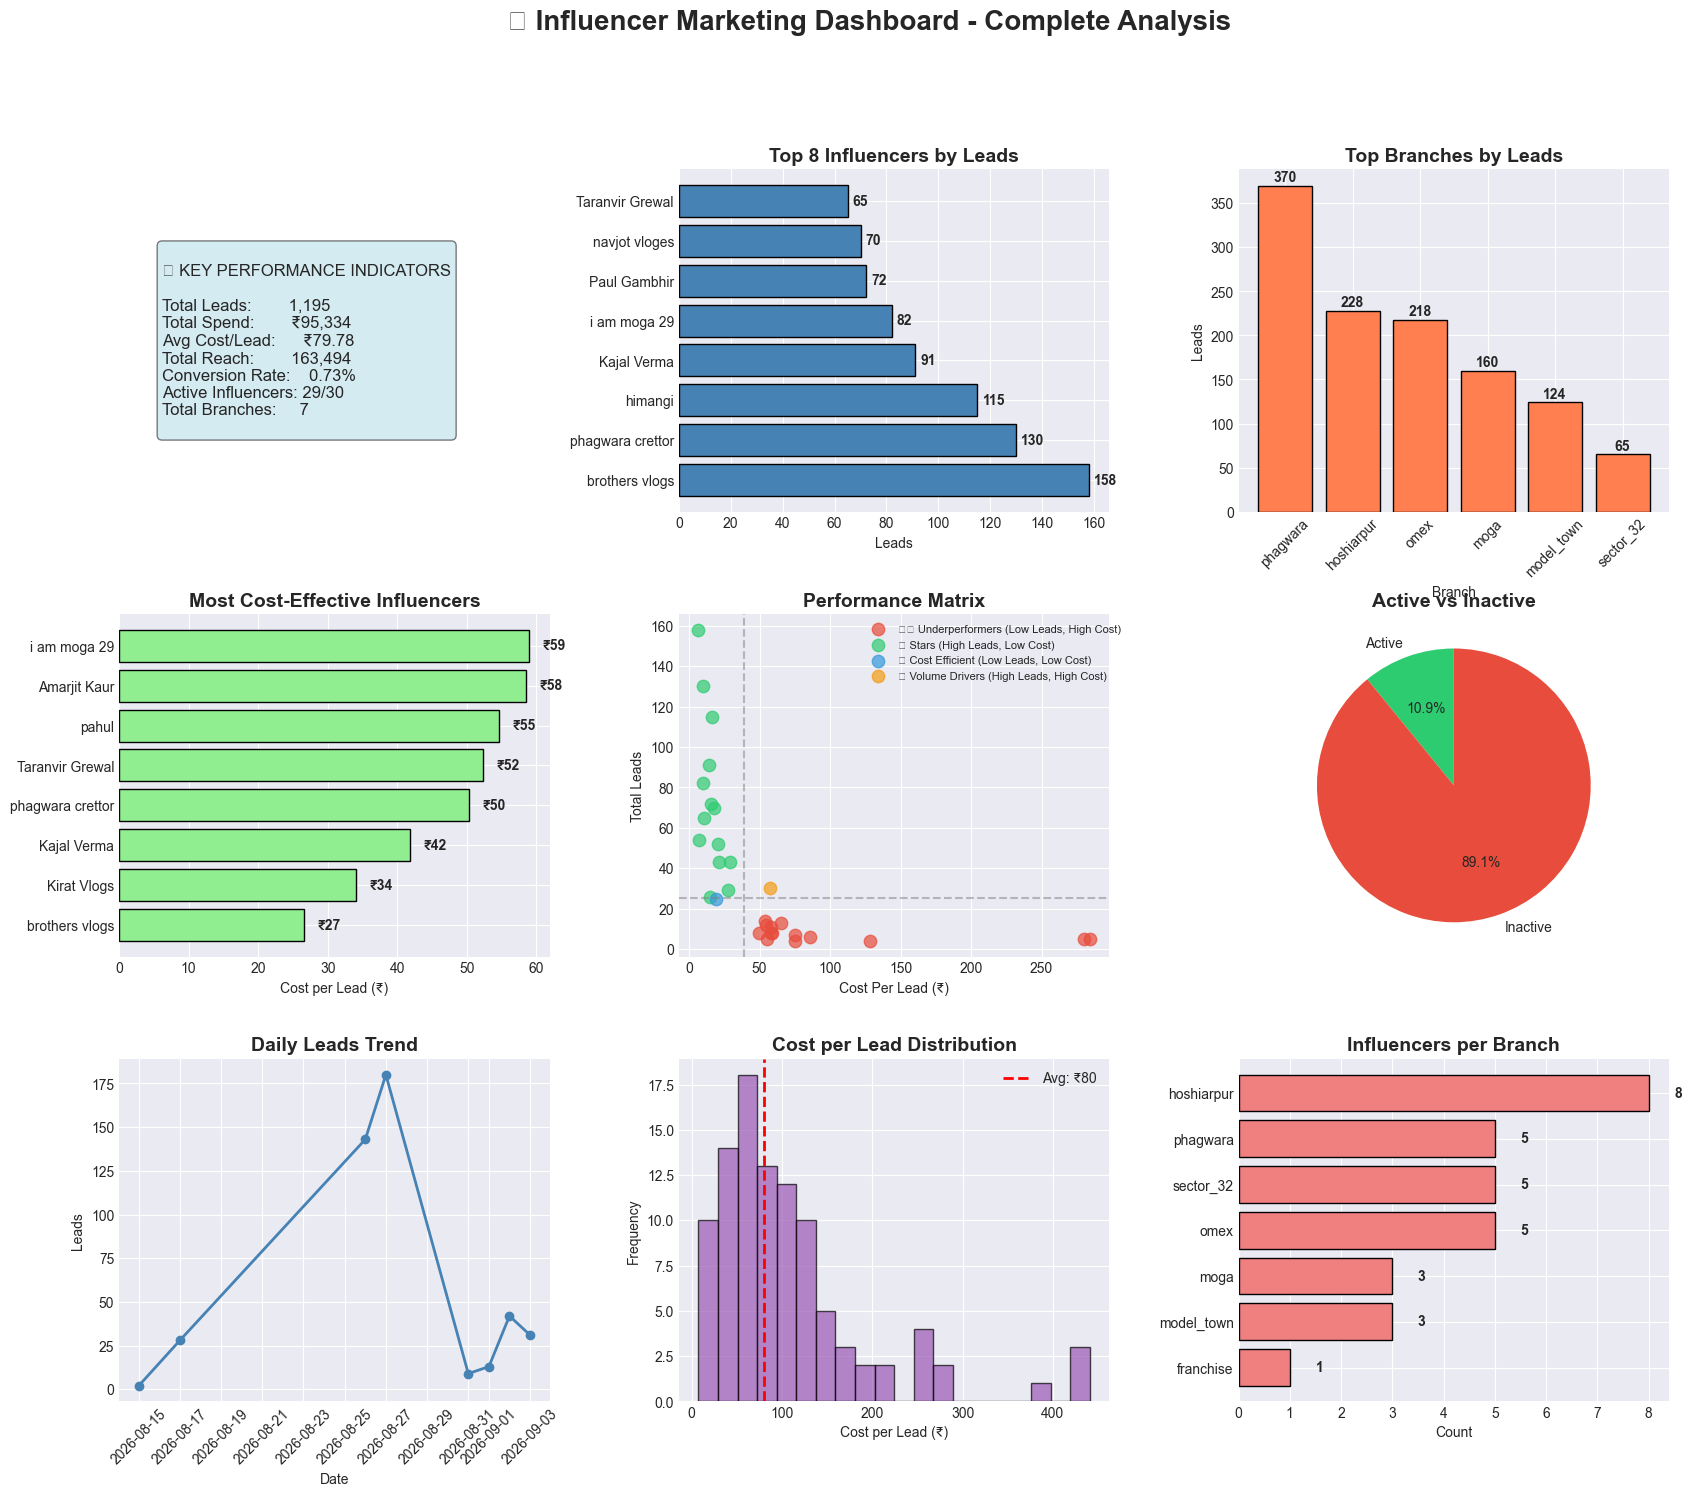

In [31]:
# Create comprehensive influencer dashboard
fig = plt.figure(figsize=(20, 16))
fig.suptitle('📊 Influencer Marketing Dashboard - Complete Analysis', 
             fontsize=20, fontweight='bold', y=0.98)

# Grid layout
gs = fig.add_gridspec(3, 3, hspace=0.3, wspace=0.3)

# 1. KPI Cards (Top Left)
ax1 = fig.add_subplot(gs[0, 0])
ax1.axis('off')
kpi_text = f"""
📈 KEY PERFORMANCE INDICATORS

Total Leads:        {total_leads:,.0f}
Total Spend:        ₹{total_spend:,.0f}
Avg Cost/Lead:      ₹{avg_cost_per_lead:,.2f}
Total Reach:        {total_reach:,.0f}
Conversion Rate:    {lead_conversion_rate:.2f}%
Active Influencers: {active_influencers}/{total_influencers}
Total Branches:     {total_branches}
"""
ax1.text(0.1, 0.5, kpi_text, transform=ax1.transAxes, fontsize=12, 
         verticalalignment='center', 
         bbox=dict(boxstyle='round', facecolor='lightblue', alpha=0.5))

# 2. Top Influencers (Top Middle)
ax2 = fig.add_subplot(gs[0, 1])
top_influencers_plot = top_influencers.head(8)
ax2.barh(top_influencers_plot['Influencer Name'], top_influencers_plot['Leads Today'], 
         color='steelblue', edgecolor='black')
ax2.set_title('Top 8 Influencers by Leads', fontsize=14, fontweight='bold')
ax2.set_xlabel('Leads')
for i, v in enumerate(top_influencers_plot['Leads Today']):
    ax2.text(v + 2, i, f'{v:.0f}', va='center', fontweight='bold')

# 3. Branch Performance (Top Right)
ax3 = fig.add_subplot(gs[0, 2])
branch_pivot = branch_performance.sort_values('Leads Today', ascending=False).head(6)
ax3.bar(branch_pivot['Branch'], branch_pivot['Leads Today'], 
        color='coral', edgecolor='black')
ax3.set_title('Top Branches by Leads', fontsize=14, fontweight='bold')
ax3.set_xlabel('Branch')
ax3.set_ylabel('Leads')
ax3.tick_params(axis='x', rotation=45)
for i, v in enumerate(branch_pivot['Leads Today']):
    ax3.text(i, v + 5, f'{v:.0f}', ha='center', fontweight='bold')

# 4. Cost Efficiency (Middle Left)
ax4 = fig.add_subplot(gs[1, 0])
cost_effective_plot = cost_effective.head(8)
ax4.barh(cost_effective_plot['Influencer Name'], cost_effective_plot['Cost_Per_Lead'], 
         color='lightgreen', edgecolor='black')
ax4.set_title('Most Cost-Effective Influencers', fontsize=14, fontweight='bold')
ax4.set_xlabel('Cost per Lead (₹)')
for i, v in enumerate(cost_effective_plot['Cost_Per_Lead']):
    ax4.text(v + 2, i, f'₹{v:.0f}', va='center', fontweight='bold')

# 5. Performance Matrix (Middle)
ax5 = fig.add_subplot(gs[1, 1])
for category in performance_matrix['Category'].unique():
    subset = performance_matrix[performance_matrix['Category'] == category]
    ax5.scatter(subset['Cost_Per_Lead'], subset['Leads Today'], 
               label=category, s=80, alpha=0.7, color=colors[category])
ax5.axhline(y=median_leads, color='gray', linestyle='--', alpha=0.5)
ax5.axvline(x=median_cost, color='gray', linestyle='--', alpha=0.5)
ax5.set_xlabel('Cost Per Lead (₹)')
ax5.set_ylabel('Total Leads')
ax5.set_title('Performance Matrix', fontsize=14, fontweight='bold')
ax5.legend(fontsize=8, bbox_to_anchor=(1.05, 1))

# 6. Status Distribution (Middle Right)
ax6 = fig.add_subplot(gs[1, 2])
labels = ['Active', 'Inactive']
counts = status_analysis['Influencer Name'].values
ax6.pie(counts, labels=labels, autopct='%1.1f%%', 
        colors=['#2ecc71', '#e74c3c'], startangle=90)
ax6.set_title('Active vs Inactive', fontsize=14, fontweight='bold')

# 7. Daily Trend (Bottom Left)
ax7 = fig.add_subplot(gs[2, 0])
ax7.plot(daily_performance['Date'], daily_performance['Leads Today'], 
         marker='o', linewidth=2, color='steelblue')
ax7.set_title('Daily Leads Trend', fontsize=14, fontweight='bold')
ax7.set_xlabel('Date')
ax7.set_ylabel('Leads')
ax7.tick_params(axis='x', rotation=45)

# 8. Cost Distribution (Bottom Middle)
ax8 = fig.add_subplot(gs[2, 1])
ax8.hist(df_clean[df_clean['Cost_Per_Lead'] < 500]['Cost_Per_Lead'], 
         bins=20, color='#9b59b6', edgecolor='black', alpha=0.7)
ax8.set_title('Cost per Lead Distribution', fontsize=14, fontweight='bold')
ax8.set_xlabel('Cost per Lead (₹)')
ax8.set_ylabel('Frequency')
ax8.axvline(x=avg_cost_per_lead, color='red', linestyle='--', 
           linewidth=2, label=f'Avg: ₹{avg_cost_per_lead:.0f}')
ax8.legend()

# 9. Influencer Count per Branch (Bottom Right)
ax9 = fig.add_subplot(gs[2, 2])
branch_count = branch_performance.sort_values('Influencer Name', ascending=True)
ax9.barh(branch_count['Branch'], branch_count['Influencer Name'], 
         color='lightcoral', edgecolor='black')
ax9.set_title('Influencers per Branch', fontsize=14, fontweight='bold')
ax9.set_xlabel('Count')
for i, v in enumerate(branch_count['Influencer Name']):
    ax9.text(v + 0.5, i, f'{v:.0f}', va='center', fontweight='bold')

plt.tight_layout()
plt.show()

In [32]:
print("\n" + "="*70)
print("💡 KEY INSIGHTS & RECOMMENDATIONS")
print("="*70)

# Generate insights
insights = []

# 1. Top performing branch
if 'branch_performance' in locals() and not branch_performance.empty:
    top_branch = branch_performance.loc[branch_performance['Leads Today'].idxmax()]
    insights.append(f"🏆 Best Performing Branch: {top_branch['Branch'].title()} with {top_branch['Leads Today']:.0f} leads")

# 2. Most cost-effective branch
if 'branch_performance' in locals() and not branch_performance.empty:
    best_cost_branch = branch_performance.loc[branch_performance['Cost_Per_Lead'].idxmin()]
    insights.append(f"💰 Most Cost-Effective Branch: {best_cost_branch['Branch'].title()} at ₹{best_cost_branch['Cost_Per_Lead']:.0f}/lead")

# 3. Top influencer
if 'top_influencers' in locals() and not top_influencers.empty:
    top_infl = top_influencers.iloc[0]
    insights.append(f"⭐ Top Influencer: {top_infl['Influencer Name']} with {top_infl['Leads Today']:.0f} leads")

# 4. Most cost-effective influencer
if 'cost_effective' in locals() and not cost_effective.empty:
    best_infl = cost_effective.iloc[0]
    insights.append(f"💎 Most Cost-Effective Influencer: {best_infl['Influencer Name']} at ₹{best_infl['Cost_Per_Lead']:.0f}/lead")

# 5. Active vs Inactive insight
if 'status_analysis' in locals() and not status_analysis.empty and 'total_leads' in locals():
    active_leads = status_analysis[status_analysis['Active'] == 1]['Leads Today'].sum()
    active_leads_pct = (active_leads / total_leads) * 100 if total_leads > 0 else 0
    insights.append(f"📊 Active Influencers generate {active_leads_pct:.1f}% of all leads")

# 6. Cost efficiency insight
if 'performance_matrix' in locals() and not performance_matrix.empty:
    cost_efficient_count = len(performance_matrix[performance_matrix['Category'] == '💰 Cost Efficient (Low Leads, Low Cost)'])
    star_count = len(performance_matrix[performance_matrix['Category'] == '⭐ Stars (High Leads, Low Cost)'])
    insights.append(f"🎯 {star_count} influencers are 'Stars' (High Leads, Low Cost)")
    insights.append(f"📈 {cost_efficient_count} influencers are cost-efficient")

# 7. Best day of the week
if 'daily_performance' in locals() and not daily_performance.empty:
    best_day = daily_performance.loc[daily_performance['Leads Today'].idxmax()]
    if 'Date' in best_day:
        insights.append(f"📅 Best Day: {best_day['Date'].strftime('%A, %d-%b')} with {best_day['Leads Today']:.0f} leads")

# 8. Total spend efficiency
if 'total_spend' in locals() and 'total_leads' in locals() and total_spend > 0:
    spend_per_lead = total_spend / total_leads if total_leads > 0 else 0
    insights.append(f"💰 Overall Cost per Lead: ₹{spend_per_lead:.2f}")

# Print insights
print("\n📊 KEY INSIGHTS:")
print("-" * 70)
for i, insight in enumerate(insights, 1):
    print(f"{i}. {insight}")

print("\n" + "="*70)
print("🚀 RECOMMENDATIONS")
print("="*70)

# Generate recommendations based on actual data
recommendations = []

# 1. Branch recommendations
if 'branch_performance' in locals() and not branch_performance.empty:
    top_branches = branch_performance.nlargest(2, 'Leads Today')['Branch'].tolist()
    if top_branches:
        recommendations.append(f"✅ Double down on top-performing branches: {', '.join([b.title() for b in top_branches])} - allocate more budget")
    
    high_cost_branches = branch_performance[branch_performance['Cost_Per_Lead'] > avg_cost_per_lead * 1.5]['Branch'].tolist()
    if high_cost_branches:
        recommendations.append(f"⚠️ Review underperforming branches: {', '.join([b.title() for b in high_cost_branches])} - high cost/lead")

# 2. Influencer recommendations
if 'cost_effective' in locals() and not cost_effective.empty and 'avg_cost_per_lead' in locals():
    target_cost = avg_cost_per_lead * 0.5
    cost_effective_list = cost_effective.head(3)['Influencer Name'].tolist()
    if cost_effective_list:
        recommendations.append(f"✅ Scale partnerships with cost-effective influencers: {', '.join(cost_effective_list)} (₹{target_cost:.0f}/lead or less)")

if 'top_influencers' in locals() and not top_influencers.empty:
    top_performers = top_influencers.head(3)['Influencer Name'].tolist()
    if top_performers:
        recommendations.append(f"⭐ Reward and retain top performers: {', '.join(top_performers)}")

# 3. Active/Inactive recommendations
if 'status_analysis' in locals() and not status_analysis.empty:
    inactive_cost = status_analysis[status_analysis['Active'] == 0]['Cost_Per_Lead'].values
    active_cost = status_analysis[status_analysis['Active'] == 1]['Cost_Per_Lead'].values
    
    if len(inactive_cost) > 0 and len(active_cost) > 0:
        if inactive_cost[0] > active_cost[0] * 1.2:
            recommendations.append("⚠️ Inactive influencers have higher cost/lead - consider replacement or renegotiation")

# 4. Cost-based recommendations
if 'performance_matrix' in locals() and not performance_matrix.empty:
    underperformers = performance_matrix[performance_matrix['Category'] == '⚠️ Underperformers (Low Leads, High Cost)']
    if not underperformers.empty:
        underperformer_names = underperformers.head(3)['Influencer Name'].tolist()
        recommendations.append(f"⚠️ Review underperforming influencers: {', '.join(underperformer_names)} - low leads, high cost")

# 5. Strategic recommendations
recommendations.extend([
    "📊 Set up automated weekly performance reviews to track daily trends",
    "🏆 Create an influencer tier system: Stars ⭐, Volume Drivers 📊, Cost-Efficient 💰, Underperformers ⚠️",
    "📈 Implement A/B testing for different content strategies to optimize conversion rates",
    "🎯 Target branches with high potential but low current performance"
])

# Print recommendations
for i, rec in enumerate(recommendations, 1):
    print(f"{i}. {rec}")

print("\n" + "="*70)

# Optional: Export insights to file
def export_insights(filename="insights_report.txt"):
    """Export insights and recommendations to a text file"""
    with open(filename, 'w') as f:
        f.write("="*70 + "\n")
        f.write("INFLUENCER MARKETING - INSIGHTS & RECOMMENDATIONS\n")
        f.write("="*70 + "\n\n")
        
        f.write("KEY INSIGHTS:\n")
        f.write("-"*70 + "\n")
        for i, insight in enumerate(insights, 1):
            f.write(f"{i}. {insight}\n")
        
        f.write("\n" + "="*70 + "\n")
        f.write("RECOMMENDATIONS\n")
        f.write("="*70 + "\n")
        for i, rec in enumerate(recommendations, 1):
            f.write(f"{i}. {rec}\n")
        
        f.write("\n" + "="*70 + "\n")
        f.write(f"Report generated on: {datetime.now().strftime('%Y-%m-%d %H:%M:%S')}\n")
    
    print(f"✅ Insights exported to: {filename}")

# Uncomment to export
# export_insights()


💡 KEY INSIGHTS & RECOMMENDATIONS

📊 KEY INSIGHTS:
----------------------------------------------------------------------
1. 🏆 Best Performing Branch: Phagwara with 370 leads
2. 💰 Most Cost-Effective Branch: Hoshiarpur at ₹52/lead
3. ⭐ Top Influencer: brothers vlogs with 158 leads
4. 💎 Most Cost-Effective Influencer: brothers vlogs at ₹27/lead
5. 📊 Active Influencers generate 81.8% of all leads
6. 🎯 14 influencers are 'Stars' (High Leads, Low Cost)
7. 📈 1 influencers are cost-efficient
8. 📅 Best Day: Thursday, 27-Aug with 180 leads
9. 💰 Overall Cost per Lead: ₹79.78

🚀 RECOMMENDATIONS
1. ✅ Double down on top-performing branches: Phagwara, Hoshiarpur - allocate more budget
2. ⚠️ Review underperforming branches: Franchise, Sector_32 - high cost/lead
3. ✅ Scale partnerships with cost-effective influencers: brothers vlogs, Kirat Vlogs, Kajal Verma (₹40/lead or less)
4. ⭐ Reward and retain top performers: brothers vlogs, phagwara crettor, himangi
5. ⚠️ Review underperforming influencers: Aa

In [33]:
print("\n" + "="*70)
print("💡 KEY INSIGHTS & RECOMMENDATIONS")
print("="*70)

# Generate insights
insights = []

# 1. Top performing branch
top_branch = branch_performance.loc[branch_performance['Leads Today'].idxmax()]
insights.append(f"🏆 Best Performing Branch: {top_branch['Branch'].title()} with {top_branch['Leads Today']:.0f} leads")

# 2. Most cost-effective branch
best_cost_branch = branch_performance.loc[branch_performance['Cost_Per_Lead'].idxmin()]
insights.append(f"💰 Most Cost-Effective Branch: {best_cost_branch['Branch'].title()} at ₹{best_cost_branch['Cost_Per_Lead']:.0f}/lead")

# 3. Top influencer
top_infl = top_influencers.iloc[0]
insights.append(f"⭐ Top Influencer: {top_infl['Influencer Name']} with {top_infl['Leads Today']:.0f} leads")

# 4. Most cost-effective influencer
best_infl = cost_effective.iloc[0]
insights.append(f"💎 Most Cost-Effective Influencer: {best_infl['Influencer Name']} at ₹{best_infl['Cost_Per_Lead']:.0f}/lead")

# 5. Active vs Inactive insight
active_leads_pct = (status_analysis[status_analysis['Active'] == 1]['Leads Today'].sum() / total_leads) * 100
insights.append(f"📊 Active Influencers generate {active_leads_pct:.1f}% of all leads")

# 6. Cost efficiency insight
cost_efficient_count = len(performance_matrix[performance_matrix['Category'] == '💰 Cost Efficient (Low Leads, Low Cost)'])
star_count = len(performance_matrix[performance_matrix['Category'] == '⭐ Stars (High Leads, Low Cost)'])
insights.append(f"🎯 {star_count} influencers are 'Stars' (High Leads, Low Cost)")
insights.append(f"📈 {cost_efficient_count} influencers are cost-efficient")

for i, insight in enumerate(insights, 1):
    print(f"{i}. {insight}")

print("\n" + "="*70)
print("🚀 RECOMMENDATIONS")
print("="*70)

recommendations = [
    "✅ Double down on top-performing branches - allocate more budget",
    "✅ Scale partnerships with cost-effective influencers (₹{:.0f}/lead or less)".format(avg_cost_per_lead * 0.5),
    "✅ Investigate why inactive influencers have higher cost/lead - replace or renegotiate",
    "✅ Set up weekly performance reviews to track daily trends",
    "✅ Create an influencer tier system: Stars, Volume Drivers, Cost-Efficient, Underperformers",
    "✅ Consider reducing spend on underperforming branches with high cost/lead"
]

for i, rec in enumerate(recommendations, 1):
    print(f"{i}. {rec}")

print("\n" + "="*70)


💡 KEY INSIGHTS & RECOMMENDATIONS
1. 🏆 Best Performing Branch: Phagwara with 370 leads
2. 💰 Most Cost-Effective Branch: Hoshiarpur at ₹52/lead
3. ⭐ Top Influencer: brothers vlogs with 158 leads
4. 💎 Most Cost-Effective Influencer: brothers vlogs at ₹27/lead
5. 📊 Active Influencers generate 81.8% of all leads
6. 🎯 14 influencers are 'Stars' (High Leads, Low Cost)
7. 📈 1 influencers are cost-efficient

🚀 RECOMMENDATIONS
1. ✅ Double down on top-performing branches - allocate more budget
2. ✅ Scale partnerships with cost-effective influencers (₹40/lead or less)
3. ✅ Investigate why inactive influencers have higher cost/lead - replace or renegotiate
4. ✅ Set up weekly performance reviews to track daily trends
5. ✅ Create an influencer tier system: Stars, Volume Drivers, Cost-Efficient, Underperformers
6. ✅ Consider reducing spend on underperforming branches with high cost/lead



In [34]:
# Export key insights to Excel for reporting
with pd.ExcelWriter('influencer_analysis_report.xlsx', engine='openpyxl') as writer:
    # Summary sheet
    summary_data = {
        'Metric': ['Total Leads', 'Total Spend', 'Avg Cost/Lead', 'Total Reach', 
                   'Conversion Rate', 'Total Influencers', 'Active Influencers', 
                   'Total Branches'],
        'Value': [total_leads, total_spend, avg_cost_per_lead, total_reach,
                  lead_conversion_rate, total_influencers, active_influencers, total_branches]
    }
    pd.DataFrame(summary_data).to_excel(writer, sheet_name='Summary', index=False)
    
    # Influencer performance
    influencer_performance.to_excel(writer, sheet_name='Influencer_Performance', index=False)
    
    # Branch performance
    branch_performance.to_excel(writer, sheet_name='Branch_Performance', index=False)
    
    # Daily performance
    daily_performance.to_excel(writer, sheet_name='Daily_Performance', index=False)
    
    # Performance matrix
    performance_matrix.to_excel(writer, sheet_name='Performance_Matrix', index=False)

print("\n📁 Report exported to: influencer_analysis_report.xlsx")



📁 Report exported to: influencer_analysis_report.xlsx


In [35]:
print("\n" + "="*70)
print("📊 KEY INSIGHTS FROM YOUR DATA")
print("="*70)

# 1. Top Performing Branches
branch_perf = df_clean.groupby('Branch').agg({
    'Leads Today': 'sum',
    'Amount Spent': 'sum',
    'Reach': 'sum'
}).reset_index()

branch_perf['Cost_Per_Lead'] = branch_perf['Amount Spent'] / branch_perf['Leads Today']

print("\n🏆 TOP BRANCHES BY LEADS:")
print(branch_perf.sort_values('Leads Today', ascending=False).head(3))

print("\n💰 MOST COST-EFFECTIVE BRANCHES:")
print(branch_perf.sort_values('Cost_Per_Lead', ascending=True).head(3))

# 2. Top Influencers
influencer_perf = df_clean.groupby('Influencer Name').agg({
    'Leads Today': 'sum',
    'Amount Spent': 'sum',
    'Reach': 'sum'
}).reset_index()

influencer_perf['Cost_Per_Lead'] = influencer_perf['Amount Spent'] / influencer_perf['Leads Today']

print("\n⭐ TOP INFLUENCERS BY LEADS:")
print(influencer_perf.sort_values('Leads Today', ascending=False).head(5))

print("\n💰 MOST COST-EFFECTIVE INFLUENCERS:")
print(influencer_perf[influencer_perf['Leads Today'] > 10].sort_values('Cost_Per_Lead', ascending=True).head(5))


📊 KEY INSIGHTS FROM YOUR DATA

🏆 TOP BRANCHES BY LEADS:
       Branch  Leads Today  Amount Spent    Reach  Cost_Per_Lead
5    phagwara        370.0      21931.00   7268.0      59.272973
1  hoshiarpur        228.0      11806.00  92566.0      51.780702
4        omex        218.0      19871.25  42436.0      91.152523

💰 MOST COST-EFFECTIVE BRANCHES:
       Branch  Leads Today  Amount Spent    Reach  Cost_Per_Lead
1  hoshiarpur        228.0       11806.0  92566.0      51.780702
5    phagwara        370.0       21931.0   7268.0      59.272973
3        moga        160.0       11914.0      0.0      74.462500

⭐ TOP INFLUENCERS BY LEADS:
     Influencer Name  Leads Today  Amount Spent    Reach  Cost_Per_Lead
16    brothers vlogs        158.0        4190.0  36496.0      26.518987
25  phagwara crettor        130.0        6541.0      0.0      50.315385
19           himangi        115.0       11190.0  21224.0      97.304348
4        Kajal Verma         91.0        3807.0      0.0      41.835165
2

In [39]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

# Assuming df_clean is your cleaned data
# Calculate influencer performance metrics
influencer_performance = df_clean.groupby('Influencer Name').agg({
    'Leads Today': 'sum',
    'Amount Spent': 'sum',
    'Reach': 'sum',
    'Cost/Lead': 'mean',
    'Branch': 'first',  # Primary branch
    'Active': 'count'   # Number of appearances
}).reset_index()

# Calculate derived metrics
influencer_performance['Cost_Per_Lead'] = influencer_performance['Amount Spent'] / influencer_performance['Leads Today']
influencer_performance['Leads_Per_Appearance'] = influencer_performance['Leads Today'] / influencer_performance['Active']
influencer_performance['Spend_Per_Appearance'] = influencer_performance['Amount Spent'] / influencer_performance['Active']
influencer_performance['Efficiency_Score'] = influencer_performance['Leads Today'] / (influencer_performance['Amount Spent'] / 1000)

# Identify bottom performers using PERCENTILE (not fixed thresholds)
# Bottom 25% = below 25th percentile
bottom_leads_threshold = influencer_performance['Leads Today'].quantile(0.25)
bottom_cost_threshold = influencer_performance['Cost_Per_Lead'].quantile(0.75)  # High cost = bad

# Define bottom performers (combination of low leads and high cost)
bottom_performers = influencer_performance[
    (influencer_performance['Leads Today'] <= bottom_leads_threshold) & 
    (influencer_performance['Cost_Per_Lead'] >= bottom_cost_threshold)
].copy()

print("="*70)
print("📊 BOTTOM PERFORMERS IDENTIFICATION")
print("="*70)
print(f"\n🔍 METHODOLOGY:")
print(f"   • Bottom 25% in Leads (≤ {bottom_leads_threshold:.1f} leads)")
print(f"   • Top 25% in Cost/Lead (≥ ₹{bottom_cost_threshold:.2f})")
print(f"\n📋 BOTTOM PERFORMERS FOUND: {len(bottom_performers)} out of {len(influencer_performance)} influencers")

print("\n" + "="*70)
print("📊 BOTTOM PERFORMERS DETAILED MATRIX")
print("="*70)
display(bottom_performers[['Influencer Name', 'Branch', 'Leads Today', 'Amount Spent', 
                          'Cost_Per_Lead', 'Reach', 'Leads_Per_Appearance']].sort_values('Leads Today'))

📊 BOTTOM PERFORMERS IDENTIFICATION

🔍 METHODOLOGY:
   • Bottom 25% in Leads (≤ 8.0 leads)
   • Top 25% in Cost/Lead (≥ ₹127.66)

📋 BOTTOM PERFORMERS FOUND: 5 out of 30 influencers

📊 BOTTOM PERFORMERS DETAILED MATRIX


,Influencer Name,Branch,Leads Today,Amount Spent,Cost_Per_Lead,Reach,Leads_Per_Appearance
24,pb10junction,sector_32,4.0,513.0,128.250000,0.0,4.0
11,PB 10 Jeaction,sector_32,5.0,1421.0,284.200000,0.0,5.0
29,yash,model_town,5.0,1400.0,280.000000,0.0,5.0
10,Manveer,hoshiarpur,6.0,1539.0,256.500000,29274.0,2.0
9,Mantya Chopra,hoshiarpur,7.0,1054.0,150.571429,0.0,3.5


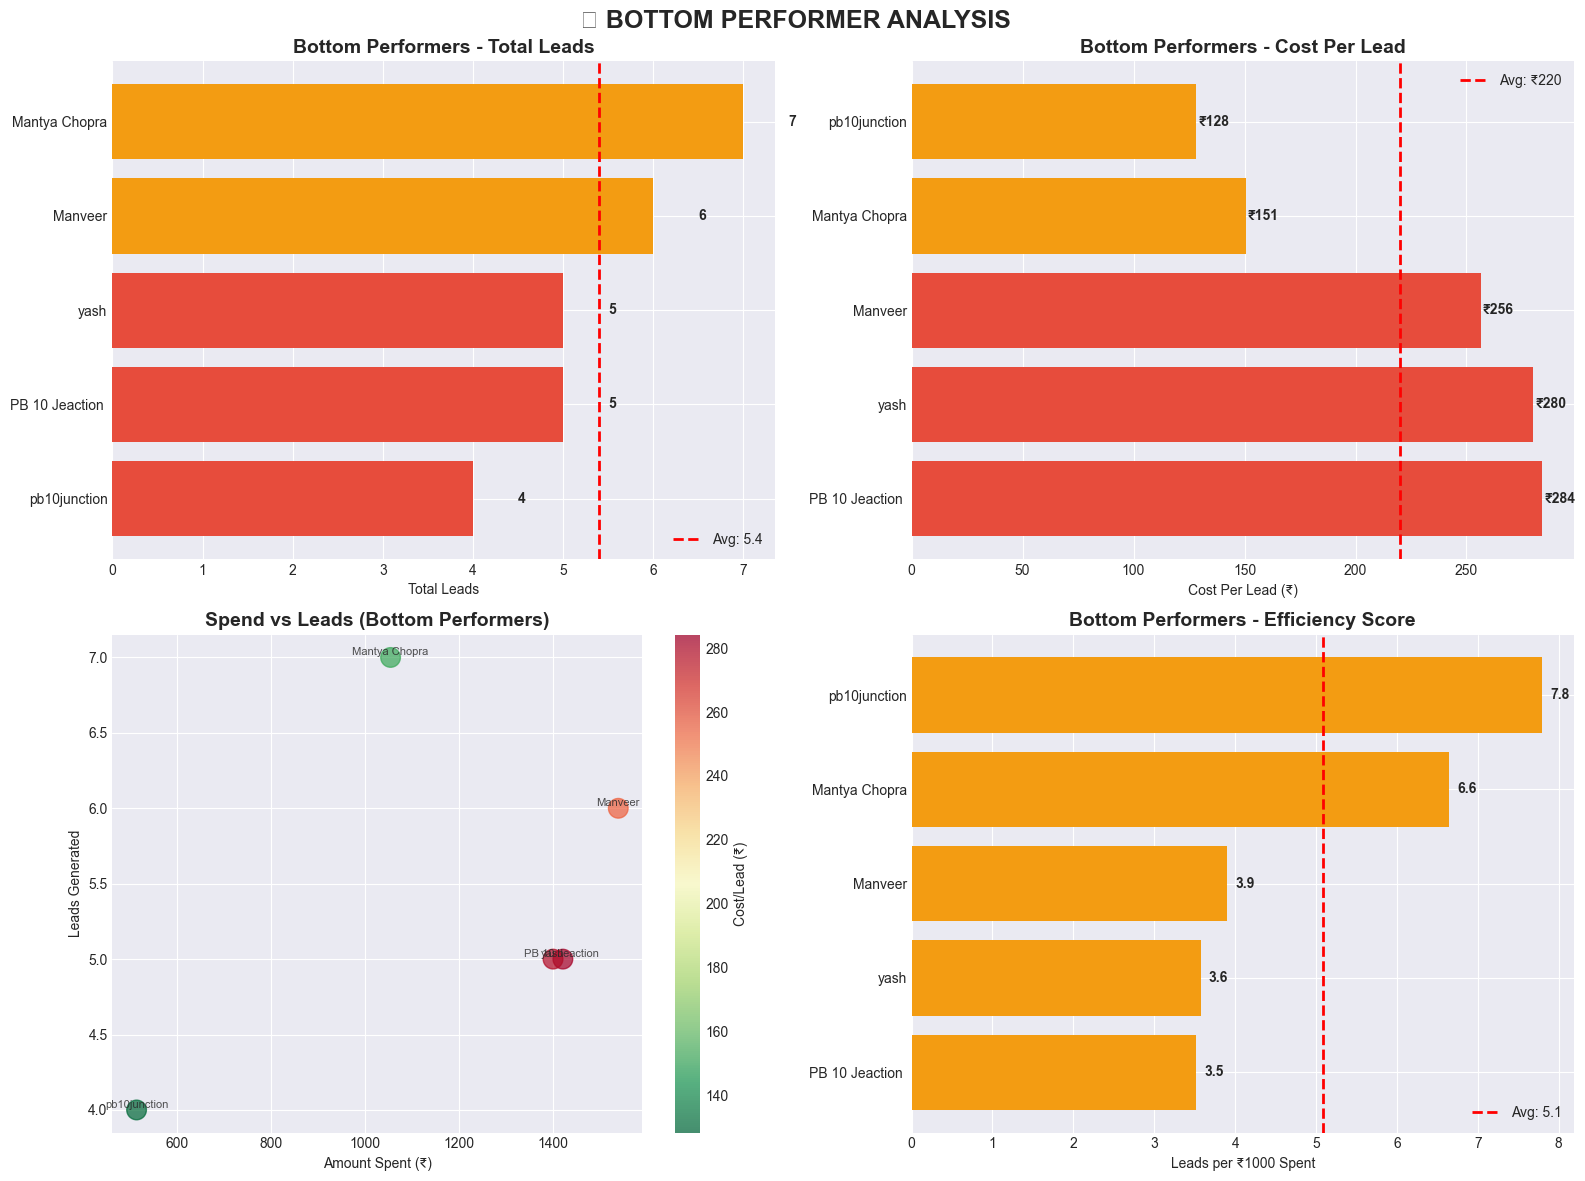

In [40]:
fig, axes = plt.subplots(2, 2, figsize=(16, 12))
fig.suptitle('📊 BOTTOM PERFORMER ANALYSIS', fontsize=18, fontweight='bold')

# 1. Bottom Performers - Leads
ax1 = axes[0, 0]
bottom_sorted = bottom_performers.sort_values('Leads Today', ascending=True)
colors = ['#e74c3c' if x < bottom_sorted['Leads Today'].mean() else '#f39c12' for x in bottom_sorted['Leads Today']]
bars = ax1.barh(bottom_sorted['Influencer Name'], bottom_sorted['Leads Today'], color=colors)
ax1.set_title('Bottom Performers - Total Leads', fontsize=14, fontweight='bold')
ax1.set_xlabel('Total Leads')
ax1.axvline(x=bottom_sorted['Leads Today'].mean(), color='red', linestyle='--', 
            linewidth=2, label=f'Avg: {bottom_sorted["Leads Today"].mean():.1f}')
ax1.legend()

for i, v in enumerate(bottom_sorted['Leads Today']):
    ax1.text(v + 0.5, i, f'{v:.0f}', va='center', fontweight='bold')

# 2. Bottom Performers - Cost Per Lead
ax2 = axes[0, 1]
bottom_cost_sorted = bottom_performers.sort_values('Cost_Per_Lead', ascending=False)
colors = ['#e74c3c' if x > bottom_cost_sorted['Cost_Per_Lead'].mean() else '#f39c12' for x in bottom_cost_sorted['Cost_Per_Lead']]
bars = ax2.barh(bottom_cost_sorted['Influencer Name'], bottom_cost_sorted['Cost_Per_Lead'], color=colors)
ax2.set_title('Bottom Performers - Cost Per Lead', fontsize=14, fontweight='bold')
ax2.set_xlabel('Cost Per Lead (₹)')
ax2.axvline(x=bottom_cost_sorted['Cost_Per_Lead'].mean(), color='red', linestyle='--', 
            linewidth=2, label=f'Avg: ₹{bottom_cost_sorted["Cost_Per_Lead"].mean():.0f}')
ax2.legend()

for i, v in enumerate(bottom_cost_sorted['Cost_Per_Lead']):
    ax2.text(v + 1, i, f'₹{v:.0f}', va='center', fontweight='bold')

# 3. Bottom Performers - Amount Spent vs Leads
ax3 = axes[1, 0]
scatter = ax3.scatter(bottom_performers['Amount Spent'], bottom_performers['Leads Today'], 
                      s=200, c=bottom_performers['Cost_Per_Lead'], 
                      cmap='RdYlGn_r', alpha=0.7)
ax3.set_title('Spend vs Leads (Bottom Performers)', fontsize=14, fontweight='bold')
ax3.set_xlabel('Amount Spent (₹)')
ax3.set_ylabel('Leads Generated')

# Add influencer names
for _, row in bottom_performers.iterrows():
    ax3.annotate(row['Influencer Name'], 
                (row['Amount Spent'], row['Leads Today']),
                fontsize=8, alpha=0.8, ha='center', va='bottom')

plt.colorbar(scatter, ax=ax3, label='Cost/Lead (₹)')

# 4. Bottom Performers - Efficiency
ax4 = axes[1, 1]
efficiency_sorted = bottom_performers.sort_values('Efficiency_Score', ascending=True)
colors = ['#e74c3c' if x < 1 else '#f39c12' for x in efficiency_sorted['Efficiency_Score']]
bars = ax4.barh(efficiency_sorted['Influencer Name'], efficiency_sorted['Efficiency_Score'], color=colors)
ax4.set_title('Bottom Performers - Efficiency Score', fontsize=14, fontweight='bold')
ax4.set_xlabel('Leads per ₹1000 Spent')
ax4.axvline(x=efficiency_sorted['Efficiency_Score'].mean(), color='red', linestyle='--', 
            linewidth=2, label=f'Avg: {efficiency_sorted["Efficiency_Score"].mean():.1f}')
ax4.legend()

for i, v in enumerate(efficiency_sorted['Efficiency_Score']):
    ax4.text(v + 0.1, i, f'{v:.1f}', va='center', fontweight='bold')

plt.tight_layout()
plt.show()

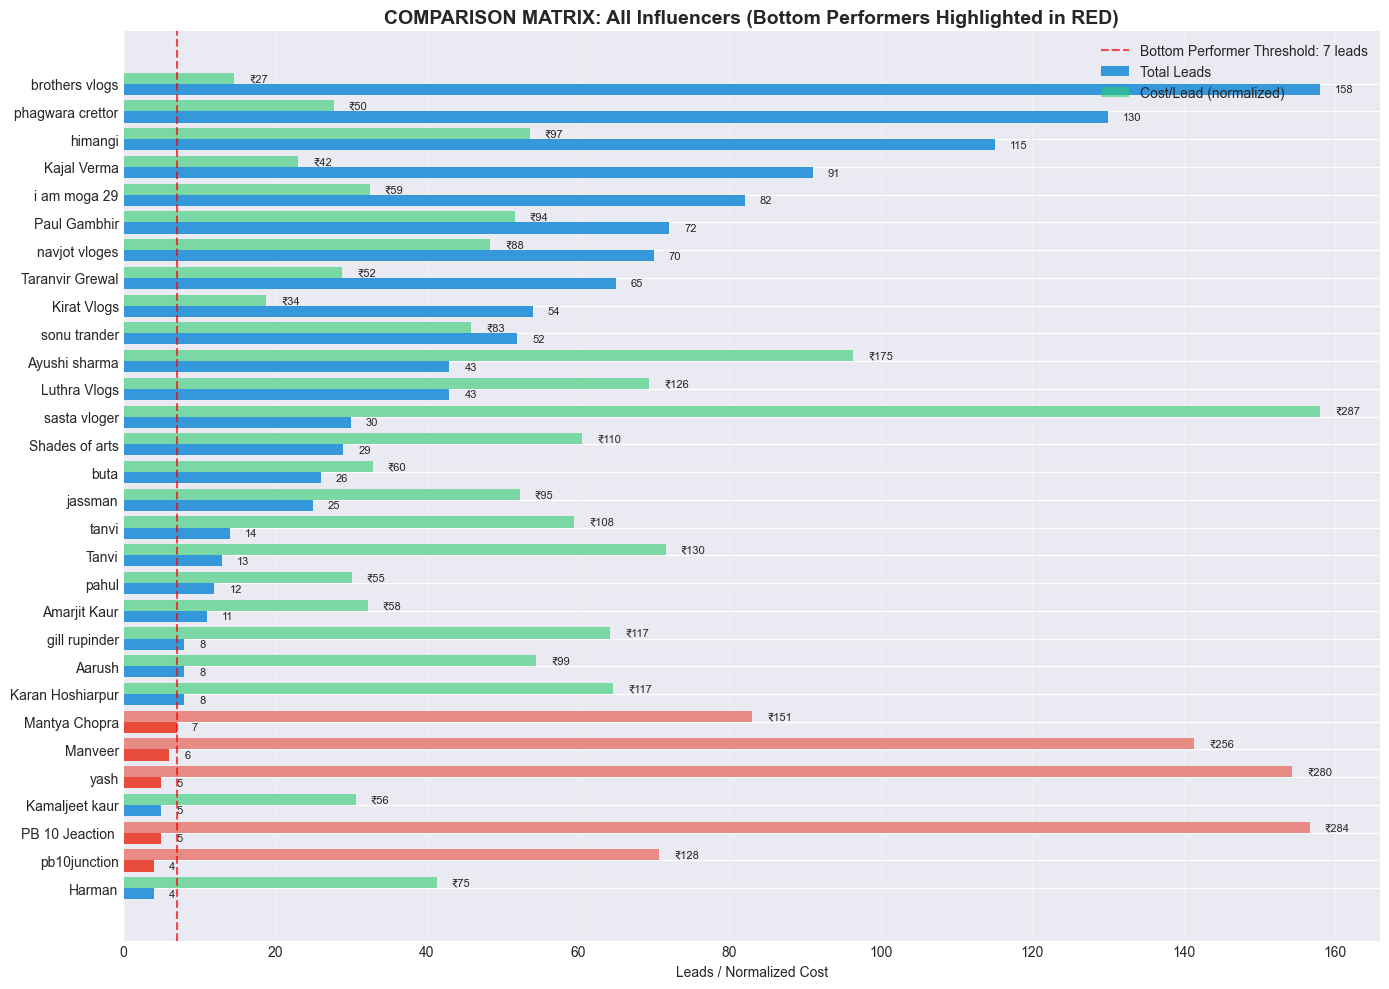

In [41]:
# Create a comprehensive comparison matrix
fig, ax = plt.subplots(figsize=(14, 10))

# Prepare data for matrix
comparison_data = influencer_performance[['Influencer Name', 'Leads Today', 'Cost_Per_Lead', 
                                          'Efficiency_Score', 'Amount Spent']].copy()

# Mark bottom performers
comparison_data['Is_Bottom'] = comparison_data['Influencer Name'].isin(bottom_performers['Influencer Name'])

# Sort by Leads (ascending to show bottom first)
comparison_data = comparison_data.sort_values('Leads Today', ascending=True)

# Create the matrix
y_pos = np.arange(len(comparison_data))
height = 0.6

# Plot bars
bars1 = ax.barh(y_pos - 0.2, comparison_data['Leads Today'], height=0.4, 
                color=['#e74c3c' if x else '#3498db' for x in comparison_data['Is_Bottom']],
                label='Total Leads')

# Normalize cost for overlay (scale to fit same axis)
max_leads = comparison_data['Leads Today'].max()
max_cost = comparison_data['Cost_Per_Lead'].max()
cost_normalized = (comparison_data['Cost_Per_Lead'] / max_cost) * max_leads

bars2 = ax.barh(y_pos + 0.2, cost_normalized, height=0.4,
                color=['#e74c3c' if x else '#2ecc71' for x in comparison_data['Is_Bottom']],
                alpha=0.6, label='Cost/Lead (normalized)')

# Add labels
ax.set_yticks(y_pos)
ax.set_yticklabels(comparison_data['Influencer Name'])
ax.set_xlabel('Leads / Normalized Cost')
ax.set_title('COMPARISON MATRIX: All Influencers (Bottom Performers Highlighted in RED)', 
             fontsize=14, fontweight='bold')

# Add value labels
for i, (leads, cost_norm) in enumerate(zip(comparison_data['Leads Today'], cost_normalized)):
    ax.text(leads + 2, i - 0.2, f'{leads:.0f}', va='center', fontsize=8)
    ax.text(cost_norm + 2, i + 0.2, f'₹{comparison_data.iloc[i]["Cost_Per_Lead"]:.0f}', 
            va='center', fontsize=8)

# Add threshold line for bottom performers
threshold_leads = bottom_performers['Leads Today'].max()
if threshold_leads > 0:
    ax.axvline(x=threshold_leads, color='red', linestyle='--', alpha=0.7,
               label=f'Bottom Performer Threshold: {threshold_leads:.0f} leads')

ax.legend(loc='upper right')
ax.grid(True, alpha=0.3, axis='x')

plt.tight_layout()
plt.show()

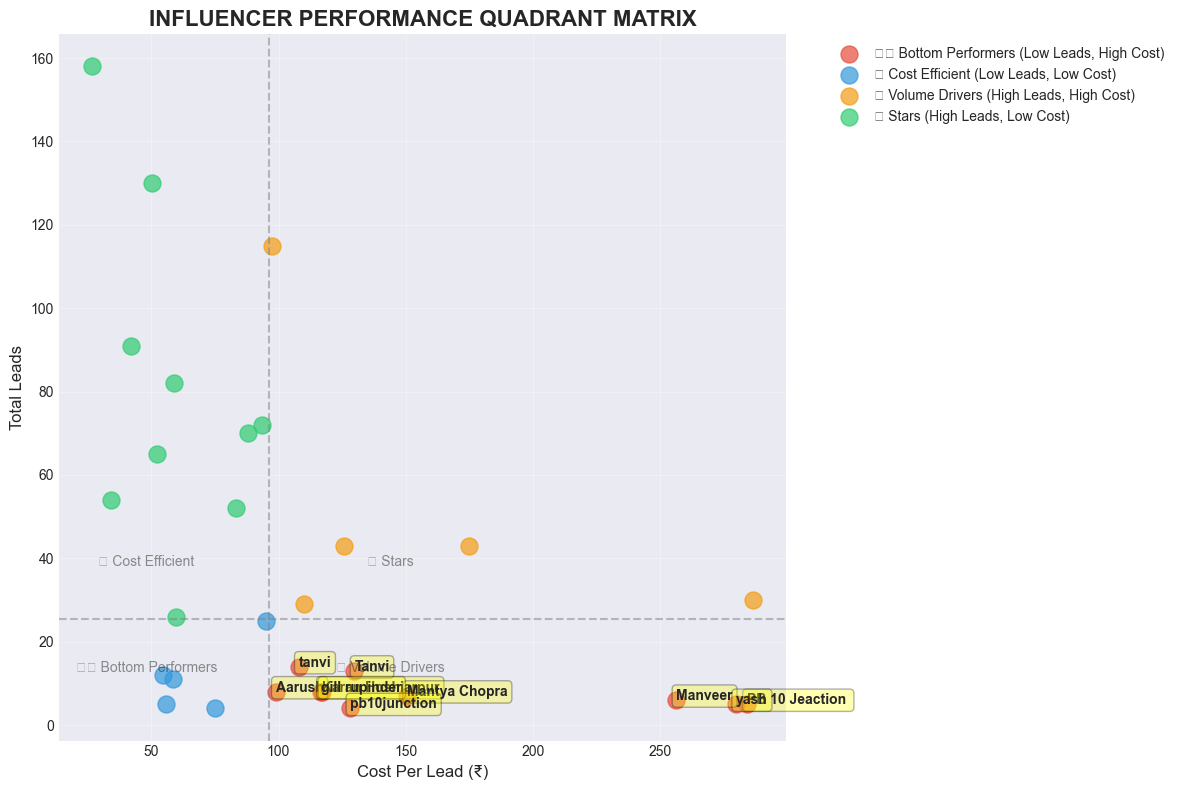


📊 PERFORMANCE QUADRANT SUMMARY


,Category,Influencer Name,Leads Today,Cost_Per_Lead
0,"⚠️ Bottom Performers (Low Leads, High Cost)",10,78.0,167.004615
1,"⭐ Stars (High Leads, Low Cost)",10,800.0,58.840225
2,"💰 Cost Efficient (Low Leads, Low Cost)",5,57.0,67.728242
3,"📊 Volume Drivers (High Leads, High Cost)",5,260.0,158.940565


In [42]:
# Create a 4-quadrant performance matrix
fig, ax = plt.subplots(figsize=(12, 8))

# Calculate medians for quadrant boundaries
median_leads = influencer_performance['Leads Today'].median()
median_cost = influencer_performance['Cost_Per_Lead'].median()

# Categorize each influencer
def categorize(row):
    if row['Leads Today'] >= median_leads and row['Cost_Per_Lead'] <= median_cost:
        return '⭐ Stars (High Leads, Low Cost)'
    elif row['Leads Today'] >= median_leads and row['Cost_Per_Lead'] > median_cost:
        return '📊 Volume Drivers (High Leads, High Cost)'
    elif row['Leads Today'] < median_leads and row['Cost_Per_Lead'] <= median_cost:
        return '💰 Cost Efficient (Low Leads, Low Cost)'
    else:
        return '⚠️ Bottom Performers (Low Leads, High Cost)'

influencer_performance['Category'] = influencer_performance.apply(categorize, axis=1)

# Plot
colors = {
    '⭐ Stars (High Leads, Low Cost)': '#2ecc71',
    '📊 Volume Drivers (High Leads, High Cost)': '#f39c12',
    '💰 Cost Efficient (Low Leads, Low Cost)': '#3498db',
    '⚠️ Bottom Performers (Low Leads, High Cost)': '#e74c3c'
}

for category in influencer_performance['Category'].unique():
    subset = influencer_performance[influencer_performance['Category'] == category]
    ax.scatter(subset['Cost_Per_Lead'], subset['Leads Today'], 
               label=category, s=150, alpha=0.7, color=colors[category])

# Highlight bottom performers
bottom_subset = influencer_performance[influencer_performance['Category'] == '⚠️ Bottom Performers (Low Leads, High Cost)']
for _, row in bottom_subset.iterrows():
    ax.annotate(row['Influencer Name'], 
                (row['Cost_Per_Lead'], row['Leads Today']),
                fontsize=10, fontweight='bold', 
                bbox=dict(boxstyle='round,pad=0.3', facecolor='yellow', alpha=0.3))

# Add quadrant lines
ax.axhline(y=median_leads, color='gray', linestyle='--', alpha=0.5)
ax.axvline(x=median_cost, color='gray', linestyle='--', alpha=0.5)

# Add quadrant labels
ax.text(median_cost/2, median_leads*1.5, '💰 Cost Efficient', fontsize=10, alpha=0.5, ha='center')
ax.text(median_cost*1.5, median_leads*1.5, '⭐ Stars', fontsize=10, alpha=0.5, ha='center')
ax.text(median_cost/2, median_leads/2, '⚠️ Bottom Performers', fontsize=10, alpha=0.5, ha='center')
ax.text(median_cost*1.5, median_leads/2, '📊 Volume Drivers', fontsize=10, alpha=0.5, ha='center')

ax.set_xlabel('Cost Per Lead (₹)', fontsize=12)
ax.set_ylabel('Total Leads', fontsize=12)
ax.set_title('INFLUENCER PERFORMANCE QUADRANT MATRIX', fontsize=16, fontweight='bold')
ax.legend(bbox_to_anchor=(1.05, 1), loc='upper left')
ax.grid(True, alpha=0.3)

plt.tight_layout()
plt.show()

# Print quadrant summary
print("\n" + "="*70)
print("📊 PERFORMANCE QUADRANT SUMMARY")
print("="*70)
quadrant_summary = influencer_performance.groupby('Category').agg({
    'Influencer Name': 'count',
    'Leads Today': 'sum',
    'Cost_Per_Lead': 'mean'
}).reset_index()
display(quadrant_summary)

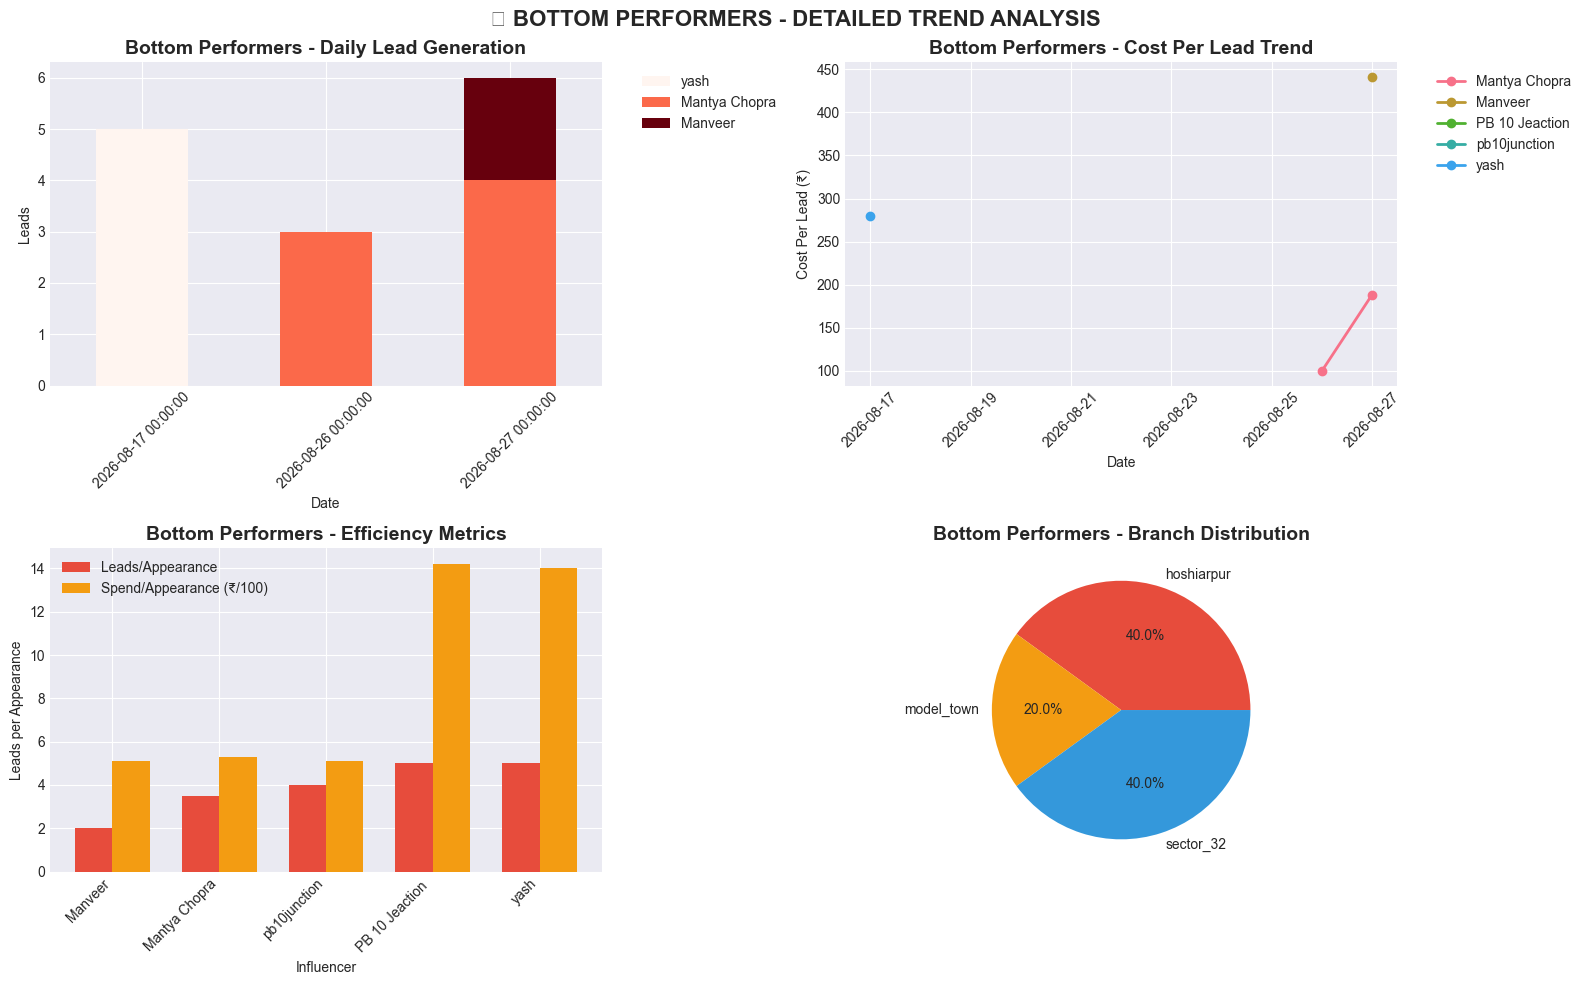

In [43]:
# Analyze bottom performers' daily performance
bottom_names = bottom_performers['Influencer Name'].tolist()
bottom_daily = df_clean[df_clean['Influencer Name'].isin(bottom_names)].copy()

if len(bottom_daily) > 0:
    fig, axes = plt.subplots(2, 2, figsize=(16, 10))
    fig.suptitle('📉 BOTTOM PERFORMERS - DETAILED TREND ANALYSIS', fontsize=16, fontweight='bold')
    
    # 1. Daily Performance of Bottom Performers
    ax1 = axes[0, 0]
    daily_summary = bottom_daily.groupby(['Date', 'Influencer Name'])['Leads Today'].sum().unstack(fill_value=0)
    daily_summary.plot(kind='bar', stacked=True, ax=ax1, colormap='Reds')
    ax1.set_title('Bottom Performers - Daily Lead Generation', fontsize=14, fontweight='bold')
    ax1.set_xlabel('Date')
    ax1.set_ylabel('Leads')
    ax1.legend(bbox_to_anchor=(1.05, 1), loc='upper left')
    ax1.tick_params(axis='x', rotation=45)
    
    # 2. Cost Trend for Bottom Performers
    ax2 = axes[0, 1]
    for influencer in bottom_names:
        inf_data = bottom_daily[bottom_daily['Influencer Name'] == influencer]
        ax2.plot(inf_data['Date'], inf_data['Cost_Per_Lead'], 
                marker='o', label=influencer, linewidth=2)
    ax2.set_title('Bottom Performers - Cost Per Lead Trend', fontsize=14, fontweight='bold')
    ax2.set_xlabel('Date')
    ax2.set_ylabel('Cost Per Lead (₹)')
    ax2.legend(bbox_to_anchor=(1.05, 1), loc='upper left')
    ax2.tick_params(axis='x', rotation=45)
    
    # 3. Lead Efficiency Comparison
    ax3 = axes[1, 0]
    efficiency_comp = bottom_performers[['Influencer Name', 'Leads_Per_Appearance', 'Spend_Per_Appearance']].sort_values('Leads_Per_Appearance')
    x = np.arange(len(efficiency_comp))
    width = 0.35
    
    bars1 = ax3.bar(x - width/2, efficiency_comp['Leads_Per_Appearance'], width, label='Leads/Appearance', color='#e74c3c')
    bars2 = ax3.bar(x + width/2, efficiency_comp['Spend_Per_Appearance']/100, width, label='Spend/Appearance (₹/100)', color='#f39c12')
    
    ax3.set_xlabel('Influencer')
    ax3.set_ylabel('Leads per Appearance')
    ax3.set_title('Bottom Performers - Efficiency Metrics', fontsize=14, fontweight='bold')
    ax3.set_xticks(x)
    ax3.set_xticklabels(efficiency_comp['Influencer Name'], rotation=45, ha='right')
    ax3.legend()
    
    # 4. Branch Distribution of Bottom Performers
    ax4 = axes[1, 1]
    branch_dist = bottom_performers.groupby('Branch').size()
    ax4.pie(branch_dist.values, labels=branch_dist.index, autopct='%1.1f%%',
            colors=['#e74c3c', '#f39c12', '#3498db', '#2ecc71'])
    ax4.set_title('Bottom Performers - Branch Distribution', fontsize=14, fontweight='bold')
    
    plt.tight_layout()
    plt.show()

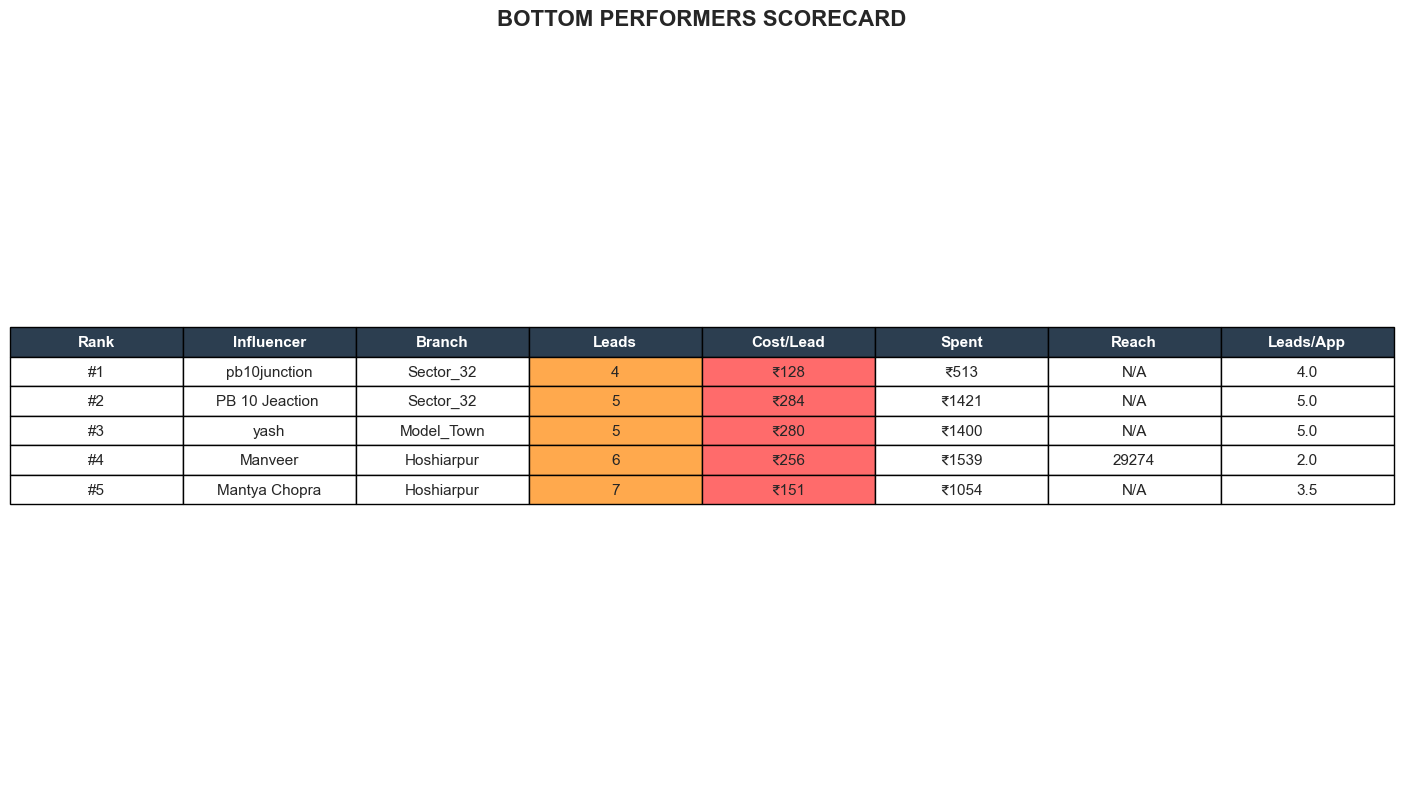

In [44]:
# Create a scorecard for bottom performers
fig, ax = plt.subplots(figsize=(14, max(8, len(bottom_performers) * 0.6)))

# Prepare data for scorecard
scorecard_data = bottom_performers[['Influencer Name', 'Branch', 'Leads Today', 'Cost_Per_Lead', 
                                    'Amount Spent', 'Reach', 'Leads_Per_Appearance']].copy()

# Add ranking
scorecard_data = scorecard_data.sort_values('Leads Today', ascending=True)
scorecard_data['Rank'] = range(1, len(scorecard_data) + 1)

# Create the table
ax.axis('tight')
ax.axis('off')

# Create table
table_data = []
headers = ['Rank', 'Influencer', 'Branch', 'Leads', 'Cost/Lead', 'Spent', 'Reach', 'Leads/App']

for _, row in scorecard_data.iterrows():
    table_data.append([
        f'#{row["Rank"]}',
        row['Influencer Name'],
        row['Branch'].title(),
        f'{row["Leads Today"]:.0f}',
        f'₹{row["Cost_Per_Lead"]:.0f}',
        f'₹{row["Amount Spent"]:.0f}',
        f'{row["Reach"]:.0f}' if row["Reach"] > 0 else 'N/A',
        f'{row["Leads_Per_Appearance"]:.1f}'
    ])

# Create the table
table = ax.table(cellText=table_data, colLabels=headers, 
                 cellLoc='center', loc='center',
                 colColours=['#2c3e50']*len(headers))

# Style the table
table.auto_set_font_size(False)
table.set_fontsize(11)
table.scale(1.2, 1.5)

# Color cells based on values
for i, row in enumerate(scorecard_data.iterrows()):
    for j, cell in enumerate(table_data[i]):
        if j == 3:  # Leads column
            table[(i+1, j)].set_facecolor('#ff6b6b' if float(cell) < 3 else '#ffa94d')
        elif j == 4:  # Cost column
            table[(i+1, j)].set_facecolor('#ff6b6b' if float(cell.replace('₹', '')) > 100 else '#ffa94d')

# Style header
for i in range(len(headers)):
    table[(0, i)].set_text_props(weight='bold', color='white')
    table[(0, i)].set_facecolor('#2c3e50')

ax.set_title('BOTTOM PERFORMERS SCORECARD', fontsize=16, fontweight='bold', pad=20)

plt.tight_layout()
plt.show()

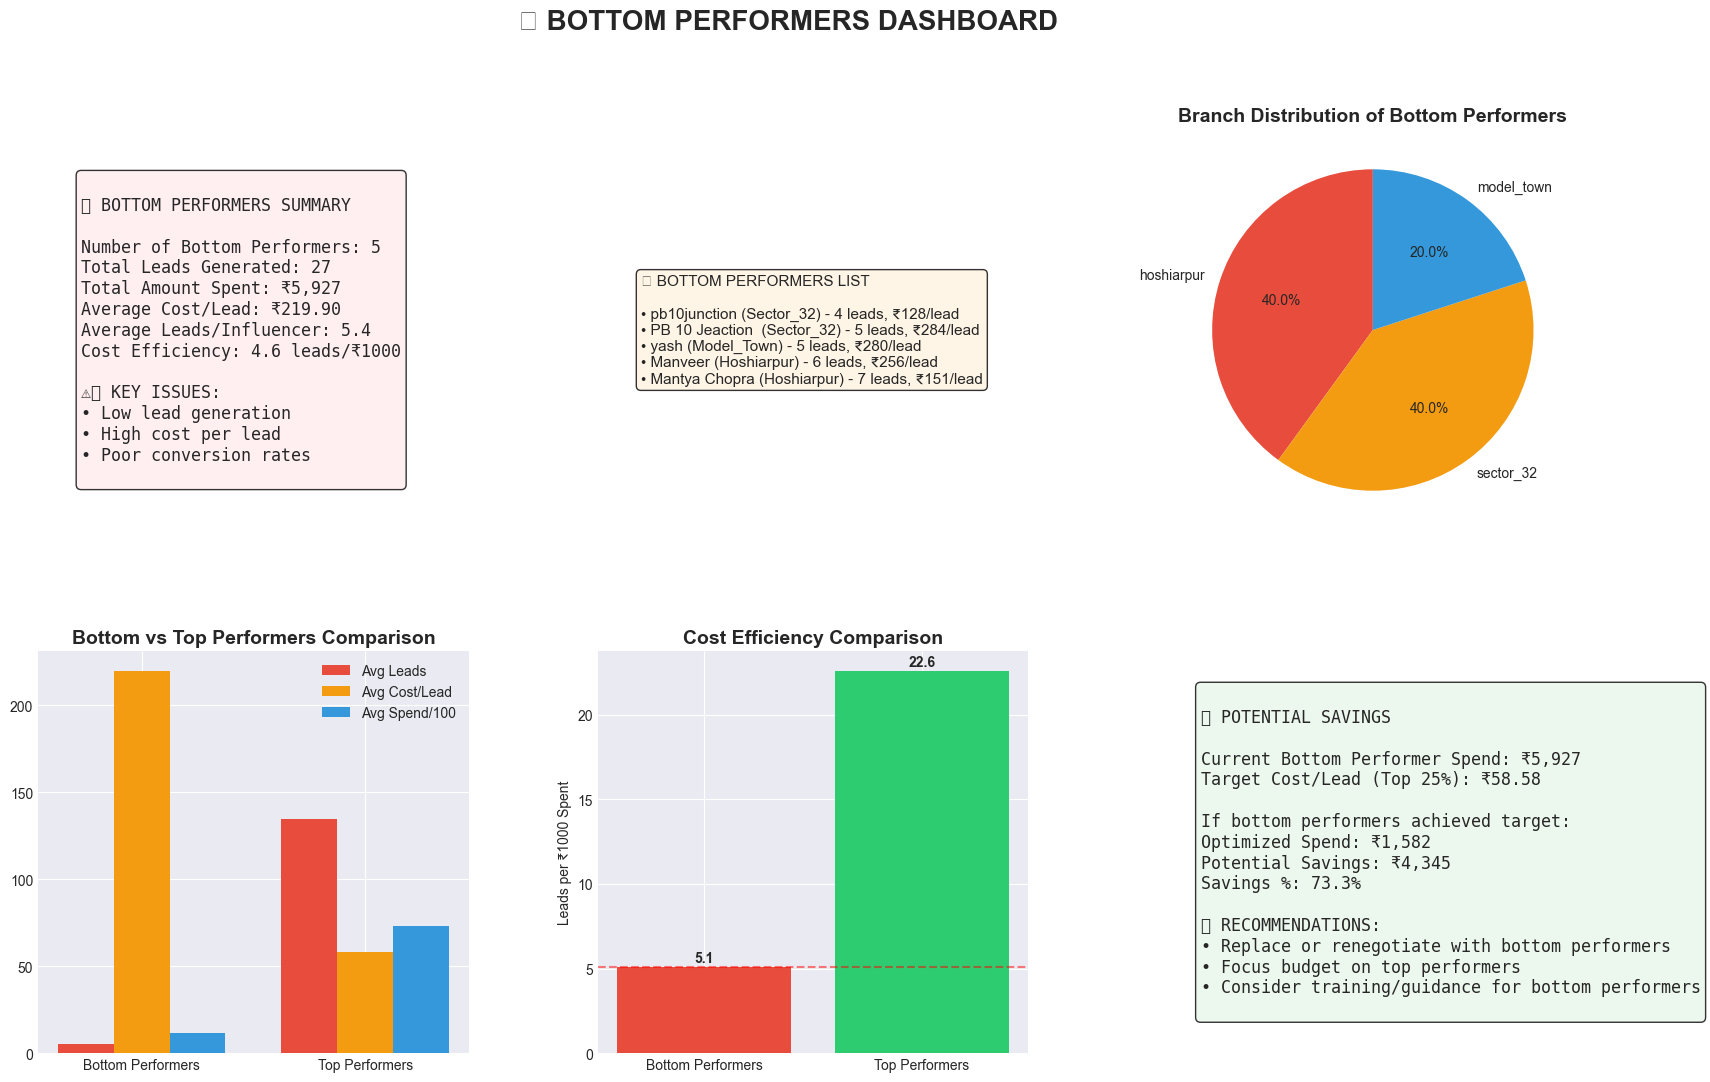

In [45]:
# Create a comprehensive summary dashboard
fig = plt.figure(figsize=(20, 12))
fig.suptitle('📊 BOTTOM PERFORMERS DASHBOARD', fontsize=20, fontweight='bold', y=0.98)

# Grid layout
gs = fig.add_gridspec(2, 3, hspace=0.3, wspace=0.3)

# 1. Summary Metrics (Top Left)
ax1 = fig.add_subplot(gs[0, 0])
ax1.axis('off')

bottom_total_leads = bottom_performers['Leads Today'].sum()
bottom_total_spend = bottom_performers['Amount Spent'].sum()
bottom_avg_cost = bottom_performers['Cost_Per_Lead'].mean()
bottom_avg_leads = bottom_performers['Leads Today'].mean()

summary_text = f"""
📉 BOTTOM PERFORMERS SUMMARY

Number of Bottom Performers: {len(bottom_performers)}
Total Leads Generated: {bottom_total_leads:.0f}
Total Amount Spent: ₹{bottom_total_spend:,.0f}
Average Cost/Lead: ₹{bottom_avg_cost:.2f}
Average Leads/Influencer: {bottom_avg_leads:.1f}
Cost Efficiency: {bottom_total_leads / (bottom_total_spend/1000):.1f} leads/₹1000

⚠️ KEY ISSUES:
• Low lead generation
• High cost per lead
• Poor conversion rates
"""
ax1.text(0.1, 0.5, summary_text, transform=ax1.transAxes, fontsize=12, 
         verticalalignment='center', fontfamily='monospace',
         bbox=dict(boxstyle='round', facecolor='#ffebee', alpha=0.8))

# 2. Bottom Performers List (Top Middle)
ax2 = fig.add_subplot(gs[0, 1])
ax2.axis('off')

bottom_list = "\n".join([f"• {row['Influencer Name']} ({row['Branch'].title()}) - {row['Leads Today']:.0f} leads, ₹{row['Cost_Per_Lead']:.0f}/lead" 
                         for _, row in bottom_performers.sort_values('Leads Today').iterrows()])

ax2.text(0.1, 0.5, f"👥 BOTTOM PERFORMERS LIST\n\n{bottom_list}", 
         transform=ax2.transAxes, fontsize=11,
         verticalalignment='center',
         bbox=dict(boxstyle='round', facecolor='#fff3e0', alpha=0.8))

# 3. Branch Distribution (Top Right)
ax3 = fig.add_subplot(gs[0, 2])
branch_counts = bottom_performers['Branch'].value_counts()
ax3.pie(branch_counts.values, labels=branch_counts.index, autopct='%1.1f%%',
        colors=['#e74c3c', '#f39c12', '#3498db', '#2ecc71', '#9b59b6', '#1abc9c', '#e67e22'],
        startangle=90)
ax3.set_title('Branch Distribution of Bottom Performers', fontsize=14, fontweight='bold')

# 4. Comparison with Top Performers (Bottom Left)
ax4 = fig.add_subplot(gs[1, 0])
top_performers = influencer_performance.sort_values('Leads Today', ascending=False).head(3)
comparison = pd.concat([
    bottom_performers.assign(Group='Bottom'),
    top_performers.assign(Group='Top')
])

avg_comparison = comparison.groupby('Group').agg({
    'Leads Today': 'mean',
    'Cost_Per_Lead': 'mean',
    'Amount Spent': 'mean'
}).reset_index()

x = np.arange(len(avg_comparison))
width = 0.25

bars1 = ax4.bar(x - width, avg_comparison['Leads Today'], width, label='Avg Leads', color='#e74c3c')
bars2 = ax4.bar(x, avg_comparison['Cost_Per_Lead'], width, label='Avg Cost/Lead', color='#f39c12')
bars3 = ax4.bar(x + width, avg_comparison['Amount Spent']/100, width, label='Avg Spend/100', color='#3498db')

ax4.set_xticks(x)
ax4.set_xticklabels(['Bottom Performers', 'Top Performers'])
ax4.set_title('Bottom vs Top Performers Comparison', fontsize=14, fontweight='bold')
ax4.legend()

# 5. Cost Efficiency Comparison (Bottom Middle)
ax5 = fig.add_subplot(gs[1, 1])
bottom_efficiency = bottom_performers['Efficiency_Score'].mean()
top_efficiency = top_performers['Efficiency_Score'].mean()

bars = ax5.bar(['Bottom Performers', 'Top Performers'], 
               [bottom_efficiency, top_efficiency],
               color=['#e74c3c', '#2ecc71'])
ax5.axhline(y=bottom_efficiency, color='red', linestyle='--', alpha=0.5)
ax5.set_title('Cost Efficiency Comparison', fontsize=14, fontweight='bold')
ax5.set_ylabel('Leads per ₹1000 Spent')
for bar in bars:
    height = bar.get_height()
    ax5.text(bar.get_x() + bar.get_width()/2., height + 0.1,
             f'{height:.1f}', ha='center', va='bottom', fontweight='bold')

# 6. Potential Savings (Bottom Right)
ax6 = fig.add_subplot(gs[1, 2])
ax6.axis('off')

# Calculate potential savings if bottom performers were replaced
target_cost = influencer_performance['Cost_Per_Lead'].quantile(0.25)  # Top 25% cost
potential_savings = (bottom_performers['Amount Spent'].sum() - 
                     (bottom_performers['Leads Today'].sum() * target_cost))

savings_text = f"""
💰 POTENTIAL SAVINGS

Current Bottom Performer Spend: ₹{bottom_total_spend:,.0f}
Target Cost/Lead (Top 25%): ₹{target_cost:.2f}

If bottom performers achieved target:
Optimized Spend: ₹{bottom_total_leads * target_cost:,.0f}
Potential Savings: ₹{potential_savings:,.0f}
Savings %: {(potential_savings/bottom_total_spend)*100:.1f}%

📌 RECOMMENDATIONS:
• Replace or renegotiate with bottom performers
• Focus budget on top performers
• Consider training/guidance for bottom performers
"""
ax6.text(0.1, 0.5, savings_text, transform=ax6.transAxes, fontsize=12,
         verticalalignment='center', fontfamily='monospace',
         bbox=dict(boxstyle='round', facecolor='#e8f5e9', alpha=0.8))

plt.tight_layout()
plt.show()